In [1]:
import itertools
import numpy as np
from tqdm import tqdm

import matplotlib.pyplot as plt
from pennylane import numpy as pp
import pandas as pd

from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression

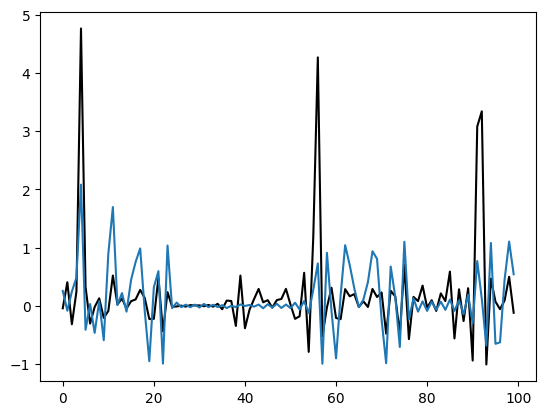

In [41]:
i = 3

X = focused_df[[c for c in focused_df.columns if c not in ("sample_id", "num_targets")]].to_numpy(dtype=np.float32)
plt.plot(X[i,:100],color="black")
X = raw_df[[c for c in raw_df.columns if c not in ("sample_id", "num_targets")]].to_numpy(dtype=np.float32)
plt.plot(X[i,:100])

In [34]:
focused_df = pd.read_csv("/home/felix/Desktop/genData/sar_focused_complex_realimag.csv")
raw_df = pd.read_csv("/home/felix/Desktop/genData/sar_raw_complex_realimag.csv")

X = focused_df[[c for c in focused_df.columns if c not in ("sample_id", "num_targets")]].to_numpy(dtype=np.float32)
y = focused_df["num_targets"].to_numpy()

clf = LogisticRegression(max_iter=1000)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(clf, X, y, cv=cv, scoring="accuracy", n_jobs=-1)
print(f"Focused 5-fold accuracy: {scores.mean():.3f} ± {scores.std():.3f}")

X = raw_df[[c for c in raw_df.columns if c not in ("sample_id", "num_targets")]].to_numpy(dtype=np.float32)
y = raw_df["num_targets"].to_numpy()

clf = LogisticRegression(max_iter=1000)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(clf, X, y, cv=cv, scoring="accuracy", n_jobs=-1)
print(f"Raw 5-fold accuracy: {scores.mean():.3f} ± {scores.std():.3f}")

Focused 5-fold accuracy: 1.000 ± 0.000
Raw 5-fold accuracy: 1.000 ± 0.000


In [37]:
EPS = 1e-12

def _complex_from_row(row, prefix):
    r = [c for c in row.index if c.startswith(f"{prefix}_real_")]
    im = [c for c in row.index if c.startswith(f"{prefix}_imag_")]
    xr = row[r].to_numpy(float)
    xi = row[im].to_numpy(float)
    return xr + 1j*xi  # (N,)

def _window_slices(N, parts):
    # equal contiguous windows
    edges = np.linspace(0, N, parts+1, dtype=int)
    return [(edges[i], edges[i+1]) for i in range(parts)]

def _mean_power(x, a, b):
    # mean |x|^2 over [a,b)
    seg = x[a:b]
    if seg.size == 0: return 0.0
    return float((np.abs(seg)**2).mean())

def _lag1_corr(x, a, b):
    # normalized lag-1 complex autocorr over [a,b)
    # use pairs (n,n+1) fully inside the window
    if b - a <= 1: return 0.0 + 0.0j
    seg = x[a:b]
    num = (seg[1:] * np.conj(seg[:-1])).sum()
    den = (np.abs(seg[1:]) * np.abs(seg[:-1])).sum() + EPS
    return num / den

def features_local_means_8(df, prefix="raw"):
    feats = []
    for _, row in df.iterrows():
        x = _complex_from_row(row, prefix)
        N = x.size

        # 4 energy features: quarters
        q_slices = _window_slices(N, 4)
        E = [ _mean_power(x, a, b) for (a,b) in q_slices ]
        Esum = sum(E) + EPS
        E = [e / Esum for e in E]  # normalize so sum(E)=1

        # 4 coherence features: left/right halves (Re/Im per half)
        h_slices = _window_slices(N, 2)
        r_left  = _lag1_corr(x, *h_slices[0])
        r_right = _lag1_corr(x, *h_slices[1])

        feats.append([
            E[0], E[1], E[2], E[3],
            float(np.real(r_left)),  float(np.imag(r_left)),
            float(np.real(r_right)), float(np.imag(r_right)),
        ])

    cols = [f"{prefix}_E{j+1}" for j in range(4)] + \
           [f"{prefix}_rL_re", f"{prefix}_rL_im", f"{prefix}_rR_re", f"{prefix}_rR_im"]
    out = pd.DataFrame(feats, columns=cols, index=df.index)
    out.insert(0, "num_targets", df["num_targets"].to_numpy())
    out.insert(0, "sample_id", df["sample_id"].to_numpy())
    return out

def to_angles_local8_linear(df, prefix="raw"):
    Ecols = [f"{prefix}_E{i}" for i in range(1,5)]
    Rcols = [f"{prefix}_rL_re", f"{prefix}_rL_im", f"{prefix}_rR_re", f"{prefix}_rR_im"]

    E = np.pi * np.clip(df[Ecols].to_numpy(float), 0.0, 1.0)
    R = np.pi * np.clip(df[Rcols].to_numpy(float), -1.0, 1.0)
    angles = np.column_stack([E, R])

    cols = [f"{prefix}_theta_E{i}" for i in range(1,5)] + \
           [f"{prefix}_theta_rL_re", f"{prefix}_theta_rL_im",
            f"{prefix}_theta_rR_re", f"{prefix}_theta_rR_im"]
    out = pd.DataFrame(angles, columns=cols, index=df.index)
    out.insert(0, "num_targets", df["num_targets"].to_numpy(int))
    out.insert(0, "sample_id",   df["sample_id"].to_numpy(int))
    return out


f_raw = to_angles_local8_linear(features_local_means_8(raw_df, prefix="raw"), prefix="raw")
f_foc = to_angles_local8_linear(features_local_means_8(focused_df, prefix="focused"), prefix="focused")
y = f_raw["num_targets"].to_numpy()

In [48]:
EPS = 1e-12

def _complex_from_row(row, prefix):
    r = [c for c in row.index if c.startswith(f"{prefix}_real_")]
    im = [c for c in row.index if c.startswith(f"{prefix}_imag_")]
    xr = row[r].to_numpy(float)
    xi = row[im].to_numpy(float)
    return xr + 1j*xi  # (N,)

def _window_slices(N, parts):
    edges = np.linspace(0, N, parts+1, dtype=int)
    return [(edges[i], edges[i+1]) for i in range(parts)]

def _mean_power(x, a, b):
    seg = x[a:b]
    if seg.size == 0: 
        return 0.0
    return float((np.abs(seg)**2).mean())

# --- Simple mean-pooling to 8 power features ---
def features_meanpool_n(df, n, prefix="raw"):
    feats = []
    for _, row in df.iterrows():
        x = _complex_from_row(row, prefix)
        slices = _window_slices(len(x), n)
        Es = [ _mean_power(x, a, b) for (a,b) in slices ]  # n values
        s = sum(Es) + EPS
        Es = [e / s for e in Es]  # L1 normalize (sum=1)
        feats.append(Es)

    cols = [f"{prefix}_E{i+1}" for i in range(n)]
    out = pd.DataFrame(feats, columns=cols, index=df.index)
    # keep your metadata columns if present
    if "sample_id" in df.columns:
        out.insert(0, "sample_id", df["sample_id"].to_numpy())
    if "num_targets" in df.columns:
        out.insert(1 if "sample_id" in out.columns else 0, "num_targets", df["num_targets"].to_numpy())
    return out

def to_angles_pool_n_linear(df, n, prefix="raw"):
    Ecols = [f"{prefix}_E{i}" for i in range(1,n+1)]  # 8 pooled energies, each in [0,1], sum≈1
    E = np.clip(df[Ecols].to_numpy(float), 0.0, 1.0)
    angles = np.pi * E  # map to [0, π]

    cols = [f"{prefix}_theta_E{i}" for i in range(1,n+1)]
    out = pd.DataFrame(angles, columns=cols, index=df.index)
    # carry metadata
    if "sample_id" in df.columns:
        out.insert(0, "sample_id", df["sample_id"].to_numpy())
    if "num_targets" in df.columns:
        out.insert(1 if "sample_id" in out.columns else 0, "num_targets", df["num_targets"].to_numpy(int))
    return out

# --- Example usage ---
n = 2
f_raw_pool = to_angles_pool_n_linear(features_meanpool_n(raw_df, prefix="raw", n=n), prefix="raw", n=n)
f_foc_pool = to_angles_pool_n_linear(features_meanpool_n(focused_df, prefix="focused", n=n), prefix="focused", n=n)
y = f_raw_pool["num_targets"].to_numpy()  # or from focused; just be consistent


In [49]:
# df = pd.read_parquet("your_transformed_df.parquet")  # or already in memory
X = f_raw[[c for c in f_raw.columns if c not in ("sample_id", "num_targets")]].to_numpy(dtype=np.float32)
y = f_raw["num_targets"].to_numpy()

clf = LogisticRegression(max_iter=1000)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(clf, X, y, cv=cv, scoring="accuracy", n_jobs=-1)
print(f"Raw 5-fold accuracy: {scores.mean():.3f} ± {scores.std():.3f}")

X = f_foc[[c for c in f_foc.columns if c not in ("sample_id", "num_targets")]].to_numpy(dtype=np.float32)
y = f_foc["num_targets"].to_numpy()

clf = LogisticRegression(max_iter=1000)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(clf, X, y, cv=cv, scoring="accuracy", n_jobs=-1)
print(f"Foc 5-fold accuracy: {scores.mean():.3f} ± {scores.std():.3f}")

Raw 5-fold accuracy: 0.808 ± 0.010
Foc 5-fold accuracy: 0.810 ± 0.014


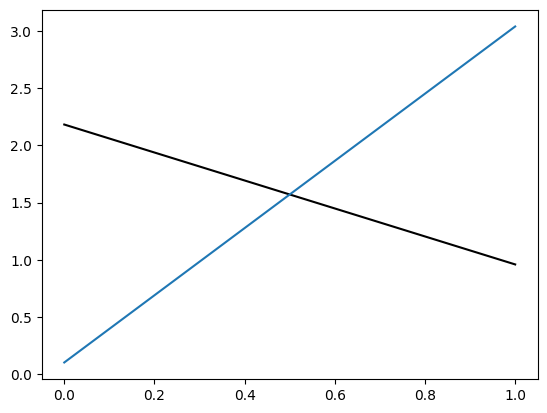

In [57]:
i = 5

X = f_raw_pool[[c for c in f_raw_pool.columns if c not in ("sample_id", "num_targets")]].to_numpy(dtype=np.float32)
plt.plot(X[i,:100],color="black")
X = f_foc_pool[[c for c in f_foc_pool.columns if c not in ("sample_id", "num_targets")]].to_numpy(dtype=np.float32)
plt.plot(X[i,:100])

In [ ]:
# import numpy as np
# import pandas as pd
# from sklearn.preprocessing import StandardScaler
# from sklearn.feature_selection import mutual_info_classif, f_classif

# def df_to_complex(df, prefix):
#     real_cols = [c for c in df.columns if c.startswith(f"{prefix}_real_")]
#     imag_cols = [c for c in df.columns if c.startswith(f"{prefix}_imag_")]
#     Xr = df[real_cols].to_numpy(dtype=np.float64)
#     Xi = df[imag_cols].to_numpy(dtype=np.float64)
#     return Xr + 1j*Xi  # shape: (n_samples, N)

# def unitary_fft(Xc):
#     # Xc: (n, N) complex
#     N = Xc.shape[1]
#     return np.fft.fft(Xc, axis=1) / np.sqrt(N)  # unitary scaling

# # -------- Method A: Complex PCA (4 complex => 8 real) --------
# class ComplexPCA8:
#     def __init__(self, n_complex=4):
#         self.n_complex = n_complex
#         self.mean_ = None
#         self.Vh_ = None  # (k, N)

#     def fit(self, Xc):
#         Xf = unitary_fft(Xc)
#         self.mean_ = Xf.mean(axis=0, keepdims=True)
#         Xc_center = Xf - self.mean_
#         # economy SVD on complex matrix
#         U, S, Vh = np.linalg.svd(Xc_center, full_matrices=False)
#         self.Vh_ = Vh[:self.n_complex, :]  # top-k complex PCs
#         return self

#     def transform(self, Xc):
#         Xf = unitary_fft(Xc) - self.mean_
#         # complex scores: (n, k)
#         Z = Xf @ self.Vh_.conj().T
#         # 4 complex -> 8 real
#         return np.hstack([Z.real, Z.imag])

# # -------- Method B: Top-4 complex frequencies by ANOVA/MI --------
# class TopFreq8:
#     def __init__(self, k_complex=4, criterion="f"):
#         self.k = k_complex
#         self.criterion = criterion
#         self.idx_ = None

#     def fit(self, Xc, y):
#         Xf = unitary_fft(Xc)  # (n, N)
#         # Build real feature matrix for scoring: [Re|Im]
#         X_real = np.hstack([Xf.real, Xf.imag])  # (n, 2N)
#         if self.criterion == "mi":
#             scores = mutual_info_classif(X_real, y, discrete_features=False)
#         else:
#             scores, _ = f_classif(X_real, y)
#         # Convert back to complex-bin scores by summing Re/Im scores
#         N = Xf.shape[1]
#         scores_complex = scores[:N] + scores[N:]
#         self.idx_ = np.argsort(scores_complex)[-self.k:]  # top-k bins
#         self.idx_.sort()
#         return self

#     def transform(self, Xc):
#         Xf = unitary_fft(Xc)
#         Z = Xf[:, self.idx_]  # (n, k) complex
#         return np.hstack([Z.real, Z.imag])  # 2k = 8 real

# # -------------------- Usage --------------------
# # raw_df / focused_df with columns sample_id, num_targets, raw_real_1.., raw_imag_1..
# # raw_df = pd.read_parquet("sar_raw_complex_realimag.parquet")
# # focused_df = pd.read_parquet("sar_focused_complex_realimag.parquet")

# # choose which to use: "raw" or "focused"
# prefix = "raw"

# Xc = df_to_complex(raw_df, prefix)                  # (n, N) complex
# y  = raw_df["num_targets"].to_numpy().astype(int)

# # Option A: Complex PCA
# cpca = ComplexPCA8(n_complex=4).fit(Xc)
# X8   = cpca.transform(Xc)                           # (n, 8) real

# # Option B: Supervised top-4 complex frequencies
# tf8  = TopFreq8(k_complex=4, criterion="f").fit(Xc, y)
# X8b  = tf8.transform(Xc)                            # (n, 8) real

# # (Optional) standardize the 8D features for QML angle encoding etc.
# scaler = StandardScaler().fit(X8)
# X8_std = scaler.transform(X8)


In [ ]:


# from sklearn.linear_model import LogisticRegression
# from sklearn.metrics import accuracy_score

# m = LogisticRegression(max_iter=1000)
# m.fit(X8b[:900], y[:900])
# m.predict( X8b[900:])

# accuracy_score(y[900:], m.predict(X8b[900:]))

0.5290909090909091

In [ ]:
# arr.shape

(199, 17)

In [ ]:
# X = arr[:, :6].real

# X = normalize_rows_complex(X)
# y = np.where(arr[:, -1] == 2, 0, 1)

In [ ]:
# import numpy as np
# from sklearn.pipeline import Pipeline
# from sklearn.preprocessing import StandardScaler
# from sklearn.linear_model import LogisticRegression
# from sklearn.model_selection import StratifiedKFold, cross_val_score

# # Assume you already have X (features) and y (labels)
# # If X contains complex numbers, split into real and imaginary parts
# if np.iscomplexobj(X):
#     X_use = np.hstack([X_proc.real, X_proc.imag])
# else:
#     X_use = X_proc

# # Ensure labels are integers (0/1)
# y_use = np.asarray(y_proc, dtype=int)

# # Define linear classifier pipeline
# clf = Pipeline([
#     ("scaler", StandardScaler()),
#     ("logreg", LogisticRegression(max_iter=5000, solver="lbfgs"))
# ])

# # Perform 5-fold stratified cross-validation
# cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
# scores = cross_val_score(clf, X_use, y_use, cv=cv, scoring="accuracy", n_jobs=-1)

# print("Fold accuracies:", scores)
# print(f"Mean accuracy: {scores.mean():.4f} ± {scores.std():.4f}")


Fold accuracies: [0.975 0.925 1.    0.95  0.975]
Mean accuracy: 0.9650 ± 0.0255


In [ ]:
# if np.iscomplexobj(X):
#     X_use = np.hstack([X.real, X.imag])
# else:
#     X_use = X

# # Ensure labels are integers (0/1)
# y_use = np.asarray(y, dtype=int)

# # Define linear classifier pipeline
# clf = Pipeline([
#     ("scaler", StandardScaler()),
#     ("logreg", LogisticRegression(max_iter=5000, solver="lbfgs"))
# ])

# # Perform 5-fold stratified cross-validation
# cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
# scores = cross_val_score(clf, X_use, y_use, cv=cv, scoring="accuracy", n_jobs=-1)

# print("Fold accuracies:", scores)
# print(f"Mean accuracy: {scores.mean():.4f} ± {scores.std():.4f}")

Fold accuracies: [0.5        0.65       0.65       0.725      0.53846154]
Mean accuracy: 0.6127 ± 0.0820


In [8]:
stop

NameError: name 'stop' is not defined

In [ ]:
# Single-qubit data re-uploading classifier (16 layers, 1 feature per layer)
# Fast, simulator-free, autograd-friendly
import pennylane as qml
from pennylane import numpy as np
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score

# ---------- feature mapping ----------
def encode_features(X, mode="phase"):
    """
    Map input X -> real features shape (N,16).
    If X is complex, choose mode in {"phase","magnitude","real","imag"}.
    If X is already real with shape (N,16), it's returned as-is.
    """
    X = np.asarray(X)
    if np.iscomplexobj(X):
        if mode == "phase":
            Xr = np.angle(X)                          # in [-pi, pi]
        elif mode == "magnitude":
            Xr = np.abs(X)                             # >= 0
        elif mode == "real":
            Xr = np.real(X)
        elif mode == "imag":
            Xr = np.imag(X)
        else:
            raise ValueError("mode must be one of: phase, magnitude, real, imag")
    else:
        Xr = X
    # assert Xr.shape[1] == 16, "This setup expects 16 features"
    return Xr

def standardize_train_test(X_tr, X_te, eps=1e-8):
    mu = np.mean(X_tr, axis=0)
    sd = np.std(X_tr, axis=0)
    sd = sd + eps
    return (X_tr - mu) / sd, (X_te - mu) / sd

# ---------- single-qubit gates (vectorized application) ----------
def apply_RZ_var(psi, angle):
    # angle: scalar
    e = np.exp(-1j * angle / 2.0)
    a0 = psi[:, 0] * e
    a1 = psi[:, 1] * np.conj(e)
    return np.stack([a0, a1], axis=1)

def apply_RY_var(psi, angle):
    # angle: scalar
    c = np.cos(angle / 2.0)
    s = np.sin(angle / 2.0)
    a0 = c * psi[:, 0] - s * psi[:, 1]
    a1 = s * psi[:, 0] + c * psi[:, 1]
    return np.stack([a0, a1], axis=1)

def apply_RZ_data(psi, ang_vec):
    # ang_vec: (N,)
    e = np.exp(-1j * ang_vec / 2.0)
    a0 = psi[:, 0] * e
    a1 = psi[:, 1] * np.conj(e)
    return np.stack([a0, a1], axis=1)

def apply_RX_data(psi, ang_vec):
    # ang_vec: (N,)
    c = np.cos(ang_vec / 2.0)
    s = np.sin(ang_vec / 2.0)
    a0 = c * psi[:, 0] - 1j * s * psi[:, 1]
    a1 = -1j * s * psi[:, 0] + c * psi[:, 1]
    return np.stack([a0, a1], axis=1)

# ---------- forward pass ----------
def predict_proba_sqr(params, Xr):
    """
    params: (L=16, 5) array per layer k: [alpha_k, beta_k, gamma_k, theta_k, phi_k]
      - data encoding per feature x_k: RZ(alpha_k * x_k) -> RX(beta_k * x_k) -> RZ(gamma_k * x_k)
      - trainable block: RY(theta_k) -> RZ(phi_k)
    Xr: (N,16) real features (standardized recommended)
    returns: (N,) probabilities p(y=1) = |amp_1|^2
    """
    N, L = Xr.shape
    # assert L == 16
    psi = np.zeros((N, 2), dtype=complex)
    psi = psi + 0.0  # keep autograd happy
    psi = psi.at[:,:] if hasattr(psi, "at") else psi  # no-op; guards against JAX confusion
    psi = np.stack([np.ones(N, dtype=complex), np.zeros(N, dtype=complex)], axis=1)

    for k in range(L):
        alpha, beta, gamma, theta, phi = params[k]
        xk = Xr[:, k]

        # data encoding on feature x_k
        psi = apply_RZ_data(psi, alpha * xk)
        psi = apply_RX_data(psi, beta  * xk)
        psi = apply_RZ_data(psi, gamma * xk)

        # trainable block
        psi = apply_RY_var(psi, theta)
        psi = apply_RZ_var(psi, phi)

    # probability of measuring |1> on Z
    p1 = np.real(np.abs(psi[:, 1])**2)
    return p1

# ---------- loss / training ----------
def bce(p, y, eps=1e-8):
    p = np.clip(p, eps, 1 - eps)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

def train_sqr(X_tr, y_tr, steps=400, lr=0.05, seed=0, verbose=False):
    rng = np.random.default_rng(seed)
    # init small: helps stability
    params0 = 0.05 * rng.standard_normal((16, 5))
    params = np.array(params0, requires_grad=True)

    opt = qml.AdamOptimizer(lr)

    def loss_fn(p):
        p1 = predict_proba_sqr(p, X_tr)
        return bce(p1, y_tr)

    for t in range(steps):
        params = opt.step(loss_fn, params)
        if verbose and (t % 50 == 0 or t == steps - 1):
            print(f"step {t:4d}  loss={loss_fn(params):.6f}")
    return params

# ---------- cross-validation ----------
def crossval_sqr(X, y, mode="phase", n_splits=5, steps=400, lr=0.05, seed=123, verbose=False):
    # 1) feature mapping to real (N,16)
    Xr_all = encode_features(X, mode=mode)

    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    scores = []
    for fold, (tr, te) in enumerate(skf.split(Xr_all, y), 1):
        X_tr, X_te = Xr_all[tr], Xr_all[te]
        y_tr, y_te = y[tr], y[te]

        # 2) standardize per-fold (helps a lot)
        # X_tr, X_te = standardize_train_test(X_tr_raw, X_te_raw)

        # 3) train
        params = train_sqr(X_tr, y_tr, steps=steps, lr=lr, seed=seed+fold, verbose=verbose)

        # 4) evaluate
        p = predict_proba_sqr(params, X_te)
        y_pred = (p >= 0.5).astype(int)
        acc = accuracy_score(y_te, y_pred)
        scores.append(acc)
        print(f"Fold {fold}: accuracy = {acc:.4f}")

    print(f"Mean accuracy: {np.mean(scores):.4f} ± {np.std(scores):.4f}")
    return np.array(scores)

# ---- usage ----
# Choose an encoding mode that matches your data:
#   "phase" (default) for complex SAR-like inputs,
#   "magnitude" if reflectivity strength matters,
#   "real"/"imag" to use a specific component.
scores = crossval_sqr(X, y, mode="phase", n_splits=5, steps=500, lr=0.03, seed=123, verbose=False)


Fold 1: accuracy = 0.5500
Fold 2: accuracy = 0.6000
Fold 3: accuracy = 0.4500
Fold 4: accuracy = 0.5500
Fold 5: accuracy = 0.5897
Mean accuracy: 0.5479 ± 0.0530


In [ ]:
stop

NameError: name 'stop' is not defined

In [ ]:
# pip install pennylane scikit-learn
import pennylane as qml
from pennylane import numpy as np
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score

# -----------------------
# Data: X (n_samples, 16) complex, y (n_samples,) in {0,1}
# -----------------------
# Example placeholders; replace with your arrays
# X = ...  # complex np.ndarray shape (N, 16)
# y = ...  # int np.ndarray shape (N,), values 0/1

# Ensure correct types
X = np.asarray(X)  # complex OK
y = np.asarray(y, dtype=int)

# AmplitudeEmbedding requires each sample to have unit L2 norm


# X_norm = normalize_rows_complex(X)
# assert X_norm.shape[1] == 16, "Amplitude encoding here assumes 16 features -> 4 qubits."

# -----------------------
# Quantum model (4 qubits, amplitude encoding + variational layers)
# -----------------------

import pennylane as qml
from pennylane import numpy as np

n_qubits = 6
dev = qml.device("lightning.qubit", wires=n_qubits)  # faster drop-in device
# dev = qml.device("default.tensor", wires=n_qubits)  # faster drop-in device


def entangle_ring():
    for i in range(n_qubits):
        qml.CNOT(wires=[i, (i + 1) % n_qubits])

def variational_block(theta):
    for w in range(n_qubits):
        qml.RX(theta[w, 0], wires=w)
        qml.RY(theta[w, 1], wires=w)
        qml.RZ(theta[w, 2], wires=w)
    entangle_ring()

@qml.qnode(dev)
def qnode(x, weights):
    # qml.AmplitudeEmbedding(features=x, wires=range(n_qubits), normalize=False)
    qml.AngleEmbedding(features=x, wires=range(n_qubits))
    for l in range(weights.shape[0]):
        variational_block(weights[l])
    return qml.expval(qml.PauliZ(0))  # z in [-1, 1]

def predict_proba(weights, Xb):
    z = np.array([qnode(x, weights) for x in Xb])
    return (1.0 - z) / 2.0  # map to p(class=1)

def predict_labels(weights, Xb, threshold=0.5):
    return (predict_proba(weights, Xb) >= threshold).astype(int)


# Binary cross-entropy
def bce(p, yb, eps=1e-8):
    p = np.clip(p, eps, 1 - eps)
    return -np.mean(yb * np.log(p) + (1 - yb) * np.log(1 - p))

def train(X_train, y_train, n_layers=2, steps=200, lr=0.1, seed=0, verbose=False):
    rng = np.random.default_rng(seed)
    weights = 0.01 * rng.standard_normal((n_layers, n_qubits, 3))
    weights = qml.numpy.array(weights, requires_grad=True)

    opt = qml.AdamOptimizer(lr)

    def loss_fn(w):
        p = predict_proba(w, X_train)
        return bce(p, y_train)

    for t in range(steps):
        weights = opt.step(loss_fn, weights)
        if verbose and (t % 20 == 0 or t == steps - 1):
            print(f"step {t:4d}  loss={loss_fn(weights):.4f}")
    return weights

# -----------------------
# 5-fold stratified cross-validation
# -----------------------
def qml_crossval(Xn, y, n_splits=5, n_layers=2, steps=200, lr=0.1, seed=42, verbose=False):
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    scores = []
    for fold, (tr, te) in enumerate(skf.split(Xn, y), 1):
        X_tr, X_te = Xn[tr], Xn[te]
        y_tr, y_te = y[tr], y[te]

        weights = train(X_tr, y_tr, n_layers=n_layers, steps=steps, lr=lr, seed=seed + fold, verbose=verbose)
        y_pred = predict_labels(weights, X_te)
        acc = accuracy_score(y_te, y_pred)
        scores.append(acc)
        print(f"Fold {fold}: accuracy = {acc:.4f}")
    print(f"Mean accuracy: {np.mean(scores):.4f} ± {np.std(scores):.4f}")
    return np.array(scores)

# -----------------------
# Run CV
# -----------------------
scores = qml_crossval(
    X, y,
    n_splits=5,
    n_layers=2,   # increase for more capacity
    steps=200,    # increase for more training
    lr=0.1,
    seed=123,
    verbose=True
)


step    0  loss=0.9451
step   20  loss=0.6831
step   40  loss=0.6682
step   60  loss=0.6653


KeyboardInterrupt: 

In [9]:
# --- Faster, more accurate drop-in for your 6-real-feature setup ---

import pennylane as qml
from pennylane import numpy as np
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score

n_qubits = 6
n_layers = 1
steps = 350
lr = 0.03
l2 = 1e-4

dev = qml.device("lightning.qubit", wires=n_qubits, shots=None)

def standardize_train_test(Xtr, Xte, eps=1e-8):
    mu = np.mean(Xtr, axis=0); sd = np.std(Xtr, axis=0) + eps
    return (Xtr - mu)/sd, (Xte - mu)/sd

def entangle_ising(phi_vec):
    for i in range(n_qubits):
        qml.IsingZZ(phi_vec[i], wires=[i, (i+1) % n_qubits])

def var_block(rot_layer, zz_layer):
    for q in range(n_qubits):
        qml.RX(rot_layer[q, 0], wires=q)
        qml.RY(rot_layer[q, 1], wires=q)
        qml.RZ(rot_layer[q, 2], wires=q)
    entangle_ising(zz_layer)

@qml.qnode(dev, diff_method="adjoint", interface="autograd")
def qnode(x, scales, rot_w, zz_w):
    # trainable input scales to avoid angle aliasing
    qml.AngleEmbedding(scales * x, wires=range(n_qubits))
    for l in range(rot_w.shape[0]):
        var_block(rot_w[l], zz_w[l])
    # read out ALL qubits to avoid bottleneck
    return [qml.expval(qml.PauliZ(i)) for i in range(n_qubits)]

def sigmoid(z): return 1.0 / (1.0 + np.exp(-z))

def predict_proba(params, Xb):
    scales, rot_w, zz_w, head_w, head_b = params
    Z = np.stack([qnode(x, scales, rot_w, zz_w) for x in Xb], axis=0)  # (N,6)
    logits = Z @ head_w + head_b
    return sigmoid(logits)

def bce(p, y, eps=1e-8):
    p = np.clip(p, eps, 1 - eps)
    return -np.mean(y*np.log(p) + (1-y)*np.log(1-p))

def loss_fn(params, Xb, yb, l2=0.0):
    scales, rot_w, zz_w, head_w, head_b = params
    p = predict_proba(params, Xb)
    reg = l2*(np.sum(scales**2)+np.sum(rot_w**2)+np.sum(zz_w**2)+np.sum(head_w**2)+head_b**2)
    return bce(p, yb) + reg

def init_params(n_layers, seed=0):
    rng = np.random.default_rng(seed)
    scales = np.array(1.0 + 0.05*rng.standard_normal(n_qubits), requires_grad=True)
    rot_w  = np.array(0.05*rng.standard_normal((n_layers, n_qubits, 3)), requires_grad=True)
    zz_w   = np.array(0.05*rng.standard_normal((n_layers, n_qubits)), requires_grad=True)
    head_w = np.array(0.01*rng.standard_normal(n_qubits), requires_grad=True)
    head_b = np.array(0.0, requires_grad=True)
    return (scales, rot_w, zz_w, head_w, head_b)

def train_fold(Xtr, ytr, seed=0, verbose=False):
    params = init_params(n_layers, seed)
    opt = qml.AdamOptimizer(stepsize=lr)
    for t in range(steps):
        params = opt.step(lambda *p: loss_fn(p, Xtr, ytr, l2=l2), *params)
        if verbose and (t % 50 == 0 or t == steps-1):
            print(f"step {t:4d}  loss={loss_fn(params, Xtr, ytr, l2=l2):.5f}")
    return params

def qml_crossval_6feat(X, y, n_splits=5, seed=123, verbose=False):
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    scores = []
    for fold, (tr, te) in enumerate(skf.split(X, y), 1):
        Xtr_raw, Xte_raw = X[tr], X[te]
        ytr, yte = y[tr], y[te]
        # per-fold standardization (prevents leakage)
        Xtr, Xte = standardize_train_test(Xtr_raw, Xte_raw)
        params = train_fold(Xtr, ytr, seed=seed+fold, verbose=verbose)
        p = predict_proba(params, Xte)
        y_pred = (p >= 0.5).astype(int)
        acc = accuracy_score(yte, y_pred)
        scores.append(acc)
        print(f"Fold {fold}: accuracy = {acc:.4f}")
    print(f"Mean accuracy: {np.mean(scores):.4f} ± {np.std(scores):.4f}")
    return np.array(scores)

# Usage:
# X: (N,6) real features; y: (N,) in {0,1}
scores = qml_crossval_6feat(X, y, n_splits=5, seed=123, verbose=True)


step    0  loss=0.69163
step   50  loss=0.64671
step  100  loss=0.61932
step  150  loss=0.60796
step  200  loss=0.60622


KeyboardInterrupt: 

In [ ]:
# pip install pennylane pennylane-lightning scikit-learn
import pennylane as qml
from pennylane import numpy as np
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score

# -----------------------
# Config
# -----------------------
n_qubits = 6
n_layers = 2          # try 2–4 for more capacity
steps = 250           # try 300–500 if underfitting
lr = 0.05
l2 = 1e-4             # mild L2 regularization
seed = 123

# -----------------------
# Device (fast) + QNode
# -----------------------
dev = qml.device("lightning.qubit", wires=n_qubits, shots=None)

def entangle_ring(phi_vec):
    # phi_vec: (n_qubits,) -> ZZ between i and (i+1)
    for i in range(n_qubits):
        qml.IsingZZ(phi_vec[i], wires=[i, (i + 1) % n_qubits])

def var_block(rot_layer, zz_layer):
    # rot_layer: (n_qubits, 3) -> RX, RY, RZ per qubit
    for q in range(n_qubits):
        qml.RX(rot_layer[q, 0], wires=q)
        qml.RY(rot_layer[q, 1], wires=q)
        qml.RZ(rot_layer[q, 2], wires=q)
    entangle_ring(zz_layer)

@qml.qnode(dev, diff_method="adjoint", interface="autograd")
def qnode(x, scales, rot_weights, zz_weights):
    """
    x: (6,) real features (already standardized)
    scales: (6,) trainable input scales
    rot_weights: (L, n_qubits, 3)
    zz_weights:  (L, n_qubits)
    """
    qml.AngleEmbedding(features=scales * x, wires=range(n_qubits))
    for l in range(rot_weights.shape[0]):
        var_block(rot_weights[l], zz_weights[l])
    # Return Z-expectations for all qubits
    return [qml.expval(qml.PauliZ(i)) for i in range(n_qubits)]

# -----------------------
# Model wrappers
# -----------------------
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

def predict_proba(params, Xb):
    """
    params = (scales, rot_weights, zz_weights, head_w, head_b)
    Xb: (N,6) real
    """
    scales, rot_w, zz_w, head_w, head_b = params
    # Evaluate circuit per sample (N is small; this is fine and stable)
    z_list = [qnode(x, scales, rot_w, zz_w) for x in Xb]  # list of length N, each (6,)
    Z = np.stack(z_list, axis=0)                           # (N,6)
    logits = Z @ head_w + head_b
    return sigmoid(logits)                                  # (N,)

def bce(p, y, eps=1e-8):
    p = np.clip(p, eps, 1 - eps)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

def loss_fn(params, Xb, yb, l2=0.0):
    scales, rot_w, zz_w, head_w, head_b = params
    p = predict_proba(params, Xb)
    reg = l2 * (np.sum(scales**2) + np.sum(rot_w**2) + np.sum(zz_w**2) + np.sum(head_w**2) + head_b**2)
    return bce(p, yb) + reg

# -----------------------
# Training
# -----------------------
def standardize_train_test(Xtr, Xte, eps=1e-8):
    mu = np.mean(Xtr, axis=0)
    sd = np.std(Xtr, axis=0)
    sd = sd + eps
    return (Xtr - mu)/sd, (Xte - mu)/sd

def init_params(n_layers, rng):
    # Trainable input scales (start near 1.0)
    scales = np.array(1.0 + 0.05 * rng.standard_normal(n_qubits), requires_grad=True)

    # Rotations per layer/qubit
    rot_w = 0.05 * rng.standard_normal((n_layers, n_qubits, 3))
    rot_w = np.array(rot_w, requires_grad=True)

    # ZZ couplings per edge in ring per layer
    zz_w = 0.05 * rng.standard_normal((n_layers, n_qubits))
    zz_w = np.array(zz_w, requires_grad=True)

    # Linear readout on Z-expectations
    head_w = np.array(0.01 * rng.standard_normal(n_qubits), requires_grad=True)
    head_b = np.array(0.0, requires_grad=True)
    return (scales, rot_w, zz_w, head_w, head_b)

def train_fold(Xtr, ytr, n_layers=n_layers, steps=steps, lr=lr, l2=l2, seed=seed, verbose=False):
    rng = np.random.default_rng(seed)
    params = init_params(n_layers, rng)
    opt = qml.AdamOptimizer(stepsize=lr)

    for t in range(steps):
        params = opt.step(lambda *p: loss_fn(p, Xtr, ytr, l2=l2), *params)
        if verbose and (t % 50 == 0 or t == steps - 1):
            curr = loss_fn(params, Xtr, ytr, l2=l2)
            print(f"step {t:4d}  loss={curr:.6f}")
    return params

# -----------------------
# 5-fold CV (fast & stable)
# -----------------------
def qml_crossval_6feat(X, y, n_splits=5, n_layers=n_layers, steps=steps, lr=lr, l2=l2, seed=seed, verbose=False):
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    scores = []
    for fold, (tr, te) in enumerate(skf.split(X, y), 1):
        Xtr_raw, Xte_raw = X[tr], X[te]
        ytr, yte = y[tr], y[te]

        # Standardize within fold
        Xtr, Xte = standardize_train_test(Xtr_raw, Xte_raw)

        # Train
        params = train_fold(Xtr, ytr, n_layers=n_layers, steps=steps, lr=lr, l2=l2, seed=seed+fold, verbose=verbose)

        # Evaluate
        p = predict_proba(params, Xte)
        y_pred = (p >= 0.5).astype(int)
        acc = accuracy_score(yte, y_pred)
        scores.append(acc)
        print(f"Fold {fold}: accuracy = {acc:.4f}")

    print(f"Mean accuracy: {np.mean(scores):.4f} ± {np.std(scores):.4f}")
    return np.array(scores)

# -----------------------
# Usage:
# X: (N,6) real; y: (N,) in {0,1}
# -----------------------
scores = qml_crossval_6feat(X_proc, y_proc, n_splits=5, n_layers=2, steps=250, lr=0.05, l2=1e-4, seed=123, verbose=True)


step    0  loss=0.686614
step   50  loss=0.074157
step  100  loss=0.030430
step  150  loss=0.019537
step  200  loss=0.016616
step  249  loss=0.016311
Fold 1: accuracy = 1.0000
step    0  loss=0.689218
step   50  loss=0.087490
step  100  loss=0.031875
step  150  loss=0.022686
step  200  loss=0.018489
step  249  loss=0.017873
Fold 2: accuracy = 1.0000
step    0  loss=0.691586
step   50  loss=0.061834
step  100  loss=0.027114
step  150  loss=0.021018
step  200  loss=0.018047
step  249  loss=0.017333
Fold 3: accuracy = 1.0000
step    0  loss=0.686997
step   50  loss=0.081396
step  100  loss=0.030276
step  150  loss=0.023096
step  200  loss=0.019999
step  249  loss=0.017847
Fold 4: accuracy = 1.0000
step    0  loss=0.688045
step   50  loss=0.078340
step  100  loss=0.032573
step  150  loss=0.023338
step  200  loss=0.020951
step  249  loss=0.019365
Fold 5: accuracy = 1.0000
Mean accuracy: 1.0000 ± 0.0000


In [ ]:
stop 0.5474 ± 0.0391

In [ ]:
# pip install pennylane pennylane-lightning scikit-learn
import pennylane as qml
from pennylane import numpy as np
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score

# -----------------------
# Config
# -----------------------
n_qubits = 6
T = 2                 # number of alternating (f,x) blocks; total layers L=2T
K_queries = 8         # number of SAR query frequencies f_k
steps = 250
lr = 0.05
l2 = 1e-4
seed = 123

# -----------------------
# Device (fast) + helpers
# -----------------------
dev = qml.device("lightning.qubit", wires=n_qubits, shots=None)

def entangle_ring(phi_vec):
    # phi_vec: (n_qubits,) -> ZZ between i and (i+1)
    for i in range(n_qubits):
        qml.IsingZZ(phi_vec[i], wires=[i, (i + 1) % n_qubits])

def var_block(rot_layer, zz_layer):
    # rot_layer: (n_qubits, 3) -> RX, RY, RZ per qubit
    for q in range(n_qubits):
        qml.RX(rot_layer[q, 0], wires=q)
        qml.RY(rot_layer[q, 1], wires=q)
        qml.RZ(rot_layer[q, 2], wires=q)
    entangle_ring(zz_layer)

def encode_z_angles(vec, scales):
    # vec: (n_qubits,), scales: (n_qubits,) -> commuting Z-rotations
    # (Z-type Pauli encoders per paper; angles are linear in inputs)
    for q in range(n_qubits):
        qml.RZ(scales[q] * vec[q], wires=q)

# -----------------------
# Alternating NUDFT-aligned QNode
# -----------------------
@qml.qnode(dev, diff_method="adjoint", interface="autograd")
def qnode_nudft(f_vec, x, params):
    """
    f_vec: (n_qubits,) query frequency vector  (provided by SAR geometry)
    x    : (n_qubits,) data features           (standardized)
    params: tuple of trainables and fixeds:
        (sx, sf_fixed, rot_even, zz_even, rot_odd, zz_odd)
        - sx:       (T, n_qubits)   trainable scales for x-encoders
        - sf_fixed: (T, n_qubits)   *fixed* scales for f-encoders (not trained)
        - rot_even: (T, n_qubits, 3)
        - zz_even:  (T, n_qubits)
        - rot_odd:  (T, n_qubits, 3)
        - zz_odd:   (T, n_qubits)
    Returns scalar expectation <Z_0>, consistent with theorem/readout.
    """
    sx, sf_fixed, rot_even, zz_even, rot_odd, zz_odd = params

    for t in range(T):
        # Even: encode f (fixed \vec f-encoding)
        encode_z_angles(f_vec, sf_fixed[t])
        var_block(rot_even[t], zz_even[t])

        # Odd: encode x (trainable scales)
        encode_z_angles(x, sx[t])
        var_block(rot_odd[t], zz_odd[t])

    return qml.expval(qml.PauliZ(0))  # binary readout on qubit 0

# -----------------------
# Query-bank (replace with SAR aperture frequencies)
# -----------------------
# def make_f_bank(K, n_qubits, low=0.0, high=2.0*np.pi):
#     """
#     Simple default: 1D grid in [0, 2π), broadcast to all qubits.
#     In practice, replace with actual SAR phase-history / aperture samples
#     mapped to per-qubit angles.
#     """
#     base = np.linspace(low, high, K, endpoint=False)
#     return np.stack([np.full(n_qubits, phi) for phi in base], axis=0)  # (K, n_qubits)

# F_BANK = make_f_bank(K_queries, n_qubits)  # (K, n_qubits), constant (not trained)
def sar_frequency_bank_from_sim(xs, K=None, centered=True):
    """
    Build the SAR query bank from the simulator's frequency grid.

    xs : int
        Number of range samples in the raw line (numSamples in the MATLAB code).
    K  : Optional[int]
        If given, uniformly subsample the xs angular bins down to K queries.
    centered : bool
        If True, use ω_k = 2π*(k/xs - 0.5) ∈ [-π, π); if False, use ω_k = 2π*(k/xs).

    Returns
    -------
    F_BANK : (K, n_qubits) ndarray
        Each row is a per-qubit frequency vector f_vec = (ω_k, …, ω_k).
    """

    # Angular frequency grid matching the simulator's shiftPhases:
    # 2π*((0:xs-1)/xs - 0.5)  (centered at zero)
    if centered:
        omega = 2.0 * np.pi * (np.arange(xs) / xs - 0.5)   # shape (xs,)
    else:
        omega = 2.0 * np.pi * (np.arange(xs) / xs)         # [0, 2π)

    # Uniform subsample if K is requested
    if K is None or K >= xs:
        idx = np.arange(xs)
    else:
        idx = np.round(np.linspace(0, xs - 1, K)).astype(int)

    omega_sub = omega[idx]                                  # (K,)

    # Broadcast each ω_k across all qubits (1-D case -> same phase per qubit)
    F_BANK = np.stack([np.full(n_qubits, w) for w in omega_sub], axis=0)  # (K, n_qubits)
    return F_BANK

xs = 2048                 # example; set to your actual raw line length
K_queries = 8            # e.g., a manageable subset for training speed
F_BANK = sar_frequency_bank_from_sim(xs, K=K_queries, centered=True)
# -----------------------
# Model wrappers
# -----------------------
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

def features_from_circuit(params, x, f_bank=F_BANK):
    """Compute vector of circuit outputs v(f_k, x; theta) over all queries."""
    return np.stack([qnode_nudft(f_bank[k], x, params) for k in range(f_bank.shape[0])], axis=0)  # (K,)

def predict_proba(params, head_w, head_b, Xb, f_bank=F_BANK):
    """
    params: NUDFT-aligned circuit parameters (tuple)
    head_w: (K,) linear head over query features
    head_b: ()  bias
    Xb: (N, n_qubits) real (already standardized)
    """
    feats = [features_from_circuit(params, x, f_bank) for x in Xb]  # list of (K,)
    V = np.stack(feats, axis=0)                                    # (N, K)
    logits = V @ head_w + head_b
    return sigmoid(logits)                                         # (N,)

def bce(p, y, eps=1e-8):
    p = np.clip(p, eps, 1 - eps)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

def loss_fn(params, head_w, head_b, Xb, yb, l2=0.0):
    p = predict_proba(params, head_w, head_b, Xb)
    # L2 on trainables only (sf_fixed excluded)
    sx, sf_fixed, rot_even, zz_even, rot_odd, zz_odd = params
    reg = l2 * (
        np.sum(sx**2) +
        np.sum(rot_even**2) + np.sum(zz_even**2) +
        np.sum(rot_odd**2)  + np.sum(zz_odd**2) +
        np.sum(head_w**2) + head_b**2
    )
    return bce(p, yb) + reg

# -----------------------
# Training utils
# -----------------------
def standardize_train_test(Xtr, Xte, eps=1e-8):
    mu = np.mean(Xtr, axis=0)
    sd = np.std(Xtr, axis=0) + eps
    return (Xtr - mu)/sd, (Xte - mu)/sd

def init_params_nudft(T, rng, train_f=False):
    """
    Initialize alternating (f,x) PQC parameters.
    If train_f=False, sf_fixed has requires_grad=False to reflect fixed \vec f-encoding.
    """
    # Trainable x scales per layer/qubit
    sx = 0.5 + 0.05 * rng.standard_normal((T, n_qubits))
    sx = np.array(sx, requires_grad=True)

    # Fixed f scales per layer/qubit (set to 1.0 by default)
    sf = np.ones((T, n_qubits))
    if train_f:
        sf = np.array(sf + 0.05 * rng.standard_normal((T, n_qubits)), requires_grad=True)
    else:
        sf = np.array(sf, requires_grad=False)  # fixed encoding per paper

    # Trainable blocks (even and odd)
    rot_even = 0.05 * rng.standard_normal((T, n_qubits, 3))
    rot_odd  = 0.05 * rng.standard_normal((T, n_qubits, 3))
    zz_even  = 0.05 * rng.standard_normal((T, n_qubits))
    zz_odd   = 0.05 * rng.standard_normal((T, n_qubits))

    rot_even = np.array(rot_even, requires_grad=True)
    rot_odd  = np.array(rot_odd,  requires_grad=True)
    zz_even  = np.array(zz_even,  requires_grad=True)
    zz_odd   = np.array(zz_odd,   requires_grad=True)

    # Linear head over K query features
    head_w = np.array(0.01 * rng.standard_normal(K_queries), requires_grad=True)
    head_b = np.array(0.0, requires_grad=True)

    params = (sx, sf, rot_even, zz_even, rot_odd, zz_odd)
    return params, head_w, head_b

def train_fold(Xtr, ytr, T=T, steps=steps, lr=lr, l2=l2, seed=seed, train_f=False, verbose=False):
    rng = np.random.default_rng(seed)
    params, head_w, head_b = init_params_nudft(T, rng, train_f=train_f)
    opt = qml.AdamOptimizer(stepsize=lr)

    def _loss_wrap(*flat):
        # unpack
        idx = 0
        sx, sf, rot_even, zz_even, rot_odd, zz_odd, head_w_, head_b_ = flat
        return loss_fn((sx, sf, rot_even, zz_even, rot_odd, zz_odd), head_w_, head_b_, Xtr, ytr, l2=l2)

    flat = (*params, head_w, head_b)

    for t in range(steps):
        flat = opt.step(_loss_wrap, *flat)
        if verbose and (t % 50 == 0 or t == steps - 1):
            curr = _loss_wrap(*flat)
            print(f"step {t:4d}  loss={curr:.6f}")

    # repack
    sx, sf, rot_even, zz_even, rot_odd, zz_odd, head_w, head_b = flat
    params = (sx, sf, rot_even, zz_even, rot_odd, zz_odd)
    return params, head_w, head_b

# -----------------------
# 5-fold CV using NUDFT-aligned PQC
# -----------------------
def qml_crossval_sar(X, y, n_splits=5, T=T, steps=steps, lr=lr, l2=l2, seed=seed, verbose=False, train_f=False):
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    scores = []
    for fold, (tr, te) in enumerate(skf.split(X, y), 1):
        Xtr_raw, Xte_raw = X[tr], X[te]
        ytr, yte = y[tr], y[te]

        # Standardize within fold
        Xtr, Xte = standardize_train_test(Xtr_raw, Xte_raw)

        # Train
        params, head_w, head_b = train_fold(Xtr, ytr, T=T, steps=steps, lr=lr, l2=l2, seed=seed+fold, train_f=train_f, verbose=verbose)

        # Evaluate
        p = predict_proba(params, head_w, head_b, Xte)
        y_pred = (p >= 0.5).astype(int)
        acc = accuracy_score(yte, y_pred)
        scores.append(acc)
        print(f"Fold {fold}: accuracy = {acc:.4f}")

    print(f"Mean accuracy: {np.mean(scores):.4f} ± {np.std(scores):.4f}")
    return np.array(scores)

# -----------------------
# Usage:
# X: (N, n_qubits) real; y: (N,) in {0,1}
# Replace F_BANK with actual SAR query frequencies if available
# -----------------------
scores = qml_crossval_sar(X_proc, y_proc, n_splits=5, T=2, steps=250, lr=0.05, l2=1e-4, seed=123, verbose=True, train_f=False)


step    0  loss=0.716611
step   50  loss=0.521820
step  100  loss=0.163056
step  150  loss=0.120015
step  200  loss=0.114273
step  249  loss=0.108435
Fold 1: accuracy = 0.9750
step    0  loss=0.716759
step   50  loss=0.459153
step  100  loss=0.119475
step  150  loss=0.035514
step  200  loss=0.031606
step  249  loss=0.029566
Fold 2: accuracy = 0.9250
step    0  loss=0.715215
step   50  loss=0.440442
step  100  loss=0.139449
step  150  loss=0.116448
step  200  loss=0.111735
step  249  loss=0.109553
Fold 3: accuracy = 0.9750
step    0  loss=0.716043
step   50  loss=0.450457
step  100  loss=0.131817
step  150  loss=0.096229
step  200  loss=0.086932
step  249  loss=0.081553
Fold 4: accuracy = 0.9500
step    0  loss=0.711683
step   50  loss=0.347357
step  100  loss=0.117657
step  150  loss=0.033765
step  200  loss=0.029272
step  249  loss=0.027285
Fold 5: accuracy = 0.9500
Mean accuracy: 0.9550 ± 0.0187


In [10]:
np.arange(-3,4)

tensor([-3, -2, -1,  0,  1,  2,  3], requires_grad=True)

In [ ]:
scores = qml_crossval_sar(X, y, n_splits=5, T=2, steps=250, lr=0.05, l2=1e-4, seed=123, verbose=True, train_f=False)

step    0  loss=0.718094
step   50  loss=0.687448
step  100  loss=0.562805
step  150  loss=0.501646
step  200  loss=0.467915
step  249  loss=0.462724
Fold 1: accuracy = 0.5250
step    0  loss=0.715385
step   50  loss=0.686332
step  100  loss=0.685982
step  150  loss=0.685681
step  200  loss=0.677618
step  249  loss=0.677507
Fold 2: accuracy = 0.4000
step    0  loss=0.715642
step   50  loss=0.593225


KeyboardInterrupt: 

In [ ]:
# # Fast PQC (no simulator) for 4 qubits WITHOUT entanglement after amplitude embedding
# # Uses only the rotations on wire 0; autograd-friendly via pennylane.numpy

# from pennylane import numpy as np
# from sklearn.model_selection import StratifiedKFold
# from sklearn.metrics import accuracy_score

# # --- utils ---
# def normalize_rows_complex(A):
#     norms = np.linalg.norm(A, axis=1, keepdims=True)
#     norms = np.where(norms == 0, 1.0, norms)
#     return A / norms

# # Single-qubit rotation matrices (2x2)
# def RX(theta):
#     c = np.cos(theta/2)
#     s = np.sin(theta/2)
#     return np.array([[c, -1j*s],
#                      [-1j*s, c]], dtype=complex)

# def RY(theta):
#     c = np.cos(theta/2)
#     s = np.sin(theta/2)
#     return np.array([[c, -s],
#                      [s,  c]], dtype=complex)

# def RZ(theta):
#     e = np.exp(-1j*theta/2)
#     return np.array([[e, 0],
#                      [0, np.conj(e)]], dtype=complex)

# # Combine layers for wire 0: U0 = ∏_layers [RZ RY RX]  (layer 0 applied first)
# def U0_from_weights(w):  # w shape (n_layers, 3)
#     U = np.eye(2, dtype=complex)
#     for thx, thy, thz in w:
#         U = RZ(thz) @ RY(thy) @ RX(thx) @ U
#     return U

# # Closed-form expectation: <Z0> = sum over 8 pairs of amplitudes differing in bit0
# # We assume little-endian ordering: pairs are (0,1), (2,3), ..., (14,15).
# # p(class=1) = (1 - <Z0>) / 2
# def predict_proba_fast(weights, Xb):
#     """
#     weights: shape (n_layers, 3)  -- ONLY wire-0 angles matter (no entanglers)
#     Xb:      shape (N, 16) complex, each row L2-normalized
#     returns: shape (N,) probabilities for class 1
#     """
#     U0 = U0_from_weights(weights)
#     Z = np.array([[1.0, 0.0], [0.0, -1.0]], dtype=complex)
#     Zp = np.conj(U0.T) @ Z @ U0  # Z' = U0^\dagger Z U0

#     a0 = Xb[:, 0::2]  # amplitudes with bit0 = 0 (N, 8)
#     a1 = Xb[:, 1::2]  # amplitudes with bit0 = 1 (N, 8)

#     Z00 = Zp[0, 0]
#     Z11 = Zp[1, 1]
#     Z01 = Zp[0, 1]
#     Z10 = Zp[1, 0]

#     # expZ0 = sum_i [ Z00*|a0|^2 + Z11*|a1|^2 + Z01*conj(a0)*a1 + Z10*conj(a1)*a0 ]
#     term = (Z00 * np.sum(np.abs(a0)**2, axis=1) +
#             Z11 * np.sum(np.abs(a1)**2, axis=1) +
#             Z01 * np.sum(np.conj(a0) * a1, axis=1) +
#             Z10 * np.sum(np.conj(a1) * a0, axis=1))

#     expZ0 = np.real(term)  # expectation is real
#     p1 = (1.0 - expZ0) / 2.0
#     return p1

# # BCE loss
# def bce(p, y, eps=1e-8):
#     p = np.clip(p, eps, 1 - eps)
#     return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

# # Simple autograd-friendly training (Adam) on wire-0 params only
# def train_fast(X_train, y_train, n_layers=1, steps=100, lr=0.1, seed=0, verbose=False):
#     rng = np.random.default_rng(seed)
#     w = 0.01 * rng.standard_normal((n_layers, 3))
#     w = np.array(w, requires_grad=True)  # pl-numpy array with grad

#     opt = qml.AdamOptimizer(lr)  # uses autograd under the hood

#     def loss_fn(params):
#         p = predict_proba_fast(params, X_train)
#         return bce(p, y_train)

#     for t in range(steps):
#         w = opt.step(loss_fn, w)
#         if verbose and (t % 20 == 0 or t == steps - 1):
#             print(f"step {t:4d}  loss={loss_fn(w):.6f}")
#     return w

# # CV wrapper (uses the fast forward pass)
# def crossval_fast(X, y, n_splits=5, n_layers=1, steps=100, lr=0.1, seed=123, verbose=False):
#     skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
#     scores = []
#     for fold, (tr, te) in enumerate(skf.split(X, y), 1):
#         X_tr, X_te = X[tr], X[te]
#         y_tr, y_te = y[tr], y[te]
#         w = train_fast(X_tr, y_tr, n_layers=n_layers, steps=steps, lr=lr, seed=seed+fold, verbose=verbose)
#         p = predict_proba_fast(w, X_te)
#         y_pred = (p >= 0.5).astype(int)
#         acc = accuracy_score(y_te, y_pred)
#         scores.append(acc)
#         print(f"Fold {fold}: accuracy = {acc:.4f}")
#     print(f"Mean accuracy: {np.mean(scores):.4f} ± {np.std(scores):.4f}")
#     return np.array(scores)

# # -----------------------
# # Usage
# # X: (N,16) complex, y: (N,) {0,1}
# # -----------------------
# # X_norm = normalize_rows_complex(X)
# scores = crossval_fast(X, y, n_splits=5, n_layers=5, steps=1000, lr=0.1, seed=123, verbose=False)


Fold 1: accuracy = 0.4500
Fold 2: accuracy = 0.5750
Fold 3: accuracy = 0.6000
Fold 4: accuracy = 0.6500
Fold 5: accuracy = 0.5385
Mean accuracy: 0.5627 ± 0.0670


In [ ]:
# # Fast entangling PQC (no external simulator)
# # AmplitudeEmbedding (4 qubits) -> [ CP-ring(phis_l) -> RX/RY/RZ on qubit 0 ] x L -> <Z0>
# # Works with autograd via pennylane.numpy + qml.AdamOptimizer

# import pennylane as qml
# from pennylane import numpy as np
# from sklearn.model_selection import StratifiedKFold
# from sklearn.metrics import accuracy_score

# # ---------- utils ----------
# def normalize_rows_complex(A):
#     A = np.asarray(A)
#     norms = np.linalg.norm(A, axis=1, keepdims=True)
#     norms = np.where(norms == 0, 1.0, norms)
#     return A / norms

# # Single-qubit rotations (2x2)
# def RX(theta):
#     c = np.cos(theta/2); s = np.sin(theta/2)
#     return np.array([[c, -1j*s], [-1j*s, c]], dtype=complex)

# def RY(theta):
#     c = np.cos(theta/2); s = np.sin(theta/2)
#     return np.array([[c, -s], [s, c]], dtype=complex)

# def RZ(theta):
#     e = np.exp(-1j*theta/2)
#     return np.array([[e, 0.0], [0.0, np.conj(e)]], dtype=complex)

# def U0_from_angles(thx, thy, thz):
#     # Apply in Z-Y-X order per layer (you can change if you like)
#     return RZ(thz) @ RY(thy) @ RX(thx)

# # Precompute bit patterns for indices i=0..7 (these encode qubits 1,2,3)
# I8 = np.arange(8, dtype=int)
# B1 = (I8 & 1)
# B2 = (I8 >> 1) & 1
# B3 = (I8 >> 2) & 1

# def phase_pairs_for_layer(phis):
#     """
#     phis: array-like (4,) -> phases on edges (0-1, 1-2, 2-3, 3-0)
#     Returns d0, d1 of shape (8,) — multiplicative phases for amplitudes where bit0=0 or bit0=1.
#     """
#     phi01, phi12, phi23, phi30 = phis
#     base = phi12 * (B1 * B2) + phi23 * (B2 * B3)                 # b0 = 0 contributions
#     phase0 = base                                                # for bit0=0
#     phase1 = base + phi01 * B1 + phi30 * B3                      # for bit0=1
#     d0 = np.exp(1j * phase0)
#     d1 = np.exp(1j * phase1)
#     return d0, d1

# # ---------- forward pass with entanglement ----------
# def predict_proba_entangled(params, Xb):
#     """
#     params: shape (L, 7)  -> per layer: [thx, thy, thz, phi01, phi12, phi23, phi30]
#     Xb:     shape (N, 16) complex, each row L2-normalized
#     returns: (N,) probabilities p(y=1)
#     """
#     params = np.asarray(params)
#     L = params.shape[0]
#     # Split amplitude vector into pairs by bit0
#     a0 = Xb[:, 0::2].astype(complex)   # (N, 8) amplitudes with bit0 = 0
#     a1 = Xb[:, 1::2].astype(complex)   # (N, 8) amplitudes with bit0 = 1

#     for l in range(L):
#         thx, thy, thz, phi01, phi12, phi23, phi30 = params[l]
#         # Diagonal entangling CP-ring
#         d0, d1 = phase_pairs_for_layer(np.array([phi01, phi12, phi23, phi30]))
#         a0 = a0 * d0  # broadcast over batch
#         a1 = a1 * d1

#         # Local rotation on qubit 0 (mix within each pair)
#         U = U0_from_angles(thx, thy, thz)  # 2x2
#         a0_new = U[0, 0] * a0 + U[0, 1] * a1
#         a1_new = U[1, 0] * a0 + U[1, 1] * a1
#         a0, a1 = a0_new, a1_new

#     # ⟨Z0⟩ = Σ_i (|a0_i|^2 - |a1_i|^2)
#     expZ0 = np.real(np.sum(np.abs(a0)**2 - np.abs(a1)**2, axis=1))
#     p1 = (1.0 - expZ0) / 2.0
#     return p1

# # ---------- loss & training ----------
# def bce(p, y, eps=1e-8):
#     p = np.clip(p, eps, 1 - eps)
#     return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

# def train_entangled(X_train, y_train, n_layers=2, steps=200, lr=0.1, seed=0, verbose=False):
#     rng = np.random.default_rng(seed)
#     # Initialize small angles: [thx, thy, thz, phi01, phi12, phi23, phi30]
#     params0 = 0.01 * rng.standard_normal((n_layers, 7))
#     params = np.array(params0, requires_grad=True)  # pl-numpy array with grad

#     opt = qml.AdamOptimizer(lr)

#     def loss_fn(p):
#         p1 = predict_proba_entangled(p, X_train)
#         return bce(p1, y_train)

#     for t in range(steps):
#         params = opt.step(loss_fn, params)
#         if verbose and (t % 20 == 0 or t == steps - 1):
#             print(f"step {t:4d}  loss={loss_fn(params):.6f}")
#     return params

# # ---------- 5-fold CV ----------
# def crossval_entangled(X, y, n_splits=5, n_layers=2, steps=200, lr=0.1, seed=123, verbose=False):
#     skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
#     scores = []
#     for fold, (tr, te) in enumerate(skf.split(X, y), 1):
#         X_tr, X_te = X[tr], X[te]
#         y_tr, y_te = y[tr], y[te]
#         params = train_entangled(X_tr, y_tr, n_layers=n_layers, steps=steps, lr=lr, seed=seed+fold, verbose=verbose)
#         p = predict_proba_entangled(params, X_te)
#         y_pred = (p >= 0.5).astype(int)
#         acc = accuracy_score(y_te, y_pred)
#         scores.append(acc)
#         print(f"Fold {fold}: accuracy = {acc:.4f}")
#     print(f"Mean accuracy: {np.mean(scores):.4f} ± {np.std(scores):.4f}")
#     return np.array(scores)

# # ---------- usage ----------
# # X_norm = normalize_rows_complex(X)  # (N,16) complex
# scores = crossval_entangled(X, y, n_splits=5, n_layers=1000, steps=1, lr=0.3, seed=123, verbose=False)


Fold 1: accuracy = 0.5750
Fold 2: accuracy = 0.4500
Fold 3: accuracy = 0.5750
Fold 4: accuracy = 0.3250
Fold 5: accuracy = 0.3590
Mean accuracy: 0.4568 ± 0.1048


In [ ]:
import pennylane as qml
from pennylane import numpy as np
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score

# ---------- helpers ----------
def normalize_rows_complex(A):
    A = np.asarray(A)
    n = np.linalg.norm(A, axis=1, keepdims=True)
    n = np.where(n == 0, 1.0, n)
    return A / n

def RX(theta):
    c = np.cos(theta/2); s = np.sin(theta/2)
    return np.array([[c, -1j*s], [-1j*s, c]], dtype=complex)

def RY(theta):
    c = np.cos(theta/2); s = np.sin(theta/2)
    return np.array([[c, -s], [s, c]], dtype=complex)

def RZ(theta):
    e = np.exp(-1j*theta/2)
    return np.array([[e, 0.0], [0.0, np.conj(e)]], dtype=complex)

def U_euler(thx, thy, thz):
    # You can switch order if you like; this is Z-Y-X
    return RZ(thz) @ RY(thy) @ RX(thx)

def cp_phase_tensor(phi01, phi12, phi23, phi30):
    """
    Diagonal CP ring on (0-1, 1-2, 2-3, 3-0) as a (2,2,2,2) tensor of phases.
    Bit order: axes = (q0, q1, q2, q3), each in {0,1}.
    """
    b0 = np.arange(2).reshape(2,1,1,1)
    b1 = np.arange(2).reshape(1,2,1,1)
    b2 = np.arange(2).reshape(1,1,2,1)
    b3 = np.arange(2).reshape(1,1,1,2)
    phase = (phi01 * b0 * b1 +
             phi12 * b1 * b2 +
             phi23 * b2 * b3 +
             phi30 * b3 * b0)
    return np.exp(1j * phase)  # shape (2,2,2,2)

def apply_local(psi, U, axis):
    """
    Apply 2x2 unitary U on 'axis' qubit of psi.
    psi shape: (N,2,2,2,2). axis in {0,1,2,3} for qubits 0..3.
    """
    psi = np.moveaxis(psi, 1+axis, -1)              # bring target axis to the end
    psi = np.tensordot(psi, U.T, axes=([psi.ndim-1],[0]))
    psi = np.moveaxis(psi, -1, 1+axis)
    return psi

def z_expectations(psi):
    """
    psi: (N,2,2,2,2) complex amplitudes.
    Returns z: (N,4) with <Z_q> for q=0..3.
    Autograd-friendly (no np.take, no `.real`, no in-place writes).
    """
    P = np.abs(psi)**2  # (N,2,2,2,2)
    cols = []
    for q in range(4):
        # Move the qubit-q axis to the end -> (..., 2)
        Pm = np.moveaxis(P, 1 + q, -1)
        # Difference of probabilities for bit q = 0 minus bit q = 1
        diff = Pm[..., 0] - Pm[..., 1]     # shape (N,2,2,2)
        # Sum out the remaining three qubit axes sequentially (Autograd-safe)
        s = np.sum(diff, axis=1)
        s = np.sum(s, axis=1)
        s = np.sum(s, axis=1)              # shape (N,)
        cols.append(s)
    return np.stack(cols, axis=1)          # (N,4)



def sigmoid(x):
    return 1.0 / (1.0 + np.exp(-x))

# ---------- forward pass ----------
def predict_proba_expressive(params_circ, params_head, Xb):
    """
    params_circ: (L, 4, 3 + 1) array per layer:
      for each layer l and qubit q: [thx, thy, thz] in params_circ[l, q, :3]
      plus a shared CP ring (phi01, phi12, phi23, phi30) in params_circ[l, 0, 3]..params_circ[l, 3, 3]
      Concretely, we pack CP phases in the 'extra' slot of each qubit of the layer:
        phi01 = params_circ[l, 0, 3]
        phi12 = params_circ[l, 1, 3]
        phi23 = params_circ[l, 2, 3]
        phi30 = params_circ[l, 3, 3]
    params_head: (w: (4,), b: scalar) linear readout on z = [<Z0>,..,<Z3>]
    Xb: (N,16) complex normalized
    Returns: (N,) probabilities
    """
    L = params_circ.shape[0]
    N = Xb.shape[0]
    psi = Xb.reshape(N, 2,2,2,2).astype(complex)

    for l in range(L):
        # CP ring (diagonal entangler)
        phi01 = params_circ[l, 0, 3]
        phi12 = params_circ[l, 1, 3]
        phi23 = params_circ[l, 2, 3]
        phi30 = params_circ[l, 3, 3]
        D = cp_phase_tensor(phi01, phi12, phi23, phi30)  # (2,2,2,2)
        psi = psi * D  # broadcast over batch

        # Local rotations on every qubit
        for q in range(4):
            thx, thy, thz = params_circ[l, q, 0], params_circ[l, q, 1], params_circ[l, q, 2]
            U = U_euler(thx, thy, thz)
            psi = apply_local(psi, U, axis=q)

    # Readout: logistic on single-qubit Z expectations
    z = z_expectations(psi)                 # (N,4)
    w, b = params_head
    logits = z @ w + b
    return sigmoid(logits)

# ---------- loss & training ----------
def bce(p, y, eps=1e-8):
    p = np.clip(p, eps, 1 - eps)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

def train_expressive(X_train, y_train, n_layers=2, steps=300, lr=0.05, seed=0, verbose=False):
    rng = np.random.default_rng(seed)
    # params_circ: (L, 4, 4): [thx, thy, thz, phi*placeholder]
    params_circ = 0.01 * rng.standard_normal((n_layers, 4, 4))
    params_circ = np.array(params_circ, requires_grad=True)

    # head: weights (4,) and bias scalar
    w0 = 0.01 * rng.standard_normal(4)
    b0 = np.array(0.0)
    params_head = (np.array(w0, requires_grad=True), np.array(b0, requires_grad=True))

    opt = qml.AdamOptimizer(lr)

    def loss_fn(pc, ph):
        p = predict_proba_expressive(pc, ph, X_train)
        return bce(p, y_train)

    for t in range(steps):
        params_circ, params_head = opt.step(lambda a, b: loss_fn(a, b), params_circ, params_head)
        if verbose and (t % 50 == 0 or t == steps - 1):
            print(f"step {t:4d}  loss={loss_fn(params_circ, params_head):.6f}")

    return params_circ, params_head

# ---------- 5-fold CV ----------
def crossval_expressive(X, y, n_splits=5, n_layers=2, steps=300, lr=0.05, seed=123, verbose=False):
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    scores = []
    for fold, (tr, te) in enumerate(skf.split(X, y), 1):
        X_tr, X_te = X[tr], X[te]
        y_tr, y_te = y[tr], y[te]
        pc, ph = train_expressive(X_tr, y_tr, n_layers=n_layers, steps=steps, lr=lr, seed=seed+fold, verbose=verbose)
        p = predict_proba_expressive(pc, ph, X_te)
        y_pred = (p >= 0.5).astype(int)
        acc = accuracy_score(y_te, y_pred)
        scores.append(acc)
        print(f"Fold {fold}: accuracy = {acc:.4f}")
    print(f"Mean accuracy: {np.mean(scores):.4f} ± {np.std(scores):.4f}")
    return np.array(scores)

# ---- usage ----
# X_norm = normalize_rows_complex(X)  # (N,16) complex
scores = crossval_expressive(X, y, n_splits=5, n_layers=5, steps=1000, lr=0.3, seed=123, verbose=False)


Fold 1: accuracy = 0.5250
Fold 2: accuracy = 0.4000
Fold 3: accuracy = 0.4750
Fold 4: accuracy = 0.5500


Exception ignored in: <bound method IPythonKernel._clean_thread_parent_frames of <ipykernel.ipkernel.IPythonKernel object at 0x7841d8f56900>>
Traceback (most recent call last):
  File "/home/felix/SAR-QML/.venv/lib/python3.12/site-packages/ipykernel/ipkernel.py", line 781, in _clean_thread_parent_frames
    def _clean_thread_parent_frames(

KeyboardInterrupt: 


In [ ]:
# def construct_minimal_hamiltonians(P_n):
#     """Constructs the minimal set of diagonal single-qubit Hamiltonians whose eigenvalue sums generate P_n through differences."""
#     P_n = set(P_n)
#     elements = sorted(P_n)
    
#     # Helper function to generate all subset sums and their differences
#     def is_valid_subset(subset):
#         subset_sums = set()
#         for bits in itertools.product([0, 1], repeat=len(subset)):
#             s = sum(subset[i] for i in range(len(subset)) if bits[i])
#             subset_sums.add(s)
#         differences = set()
#         for s1 in subset_sums:
#             for s2 in subset_sums:
#                 differences.add(round(s1 - s2, 6))
#         return P_n.issubset(differences)
    
#     # Try subsets of P_n, ordered by size (smallest first)
#     for size in range(1, len(elements) + 1):
#         for subset in itertools.combinations(elements, size):
#             if is_valid_subset(subset):
#                 minimal_Lambda = list(subset)
#                 hamiltonians = {f"H_{i}": np.diag([0, minimal_Lambda[i]]) for i in range(len(minimal_Lambda))}
#                 return hamiltonians
    
#     # If no subset in P_n works, try including 0
#     elements_with_zero = sorted(P_n.union({0}))
#     for size in range(1, len(elements_with_zero) + 1):
#         for subset in itertools.combinations(elements_with_zero, size):
#             if 0 in subset and is_valid_subset(subset):
#                 minimal_Lambda = list(subset)
#                 hamiltonians = {f"H_{i}": np.diag([0, minimal_Lambda[i]]) for i in range(len(minimal_Lambda))}
#                 return hamiltonians
    
#     # Fallback: naive solution (shouldn't be reached if P_n is feasible)
#     naive_Lambda = list(P_n.union({0}))
#     hamiltonians = {f"H_{i}": np.diag([0, naive_Lambda[i]]) for i in range(len(naive_Lambda))}
#     return hamiltonians

# def verify_pqc_reconstruction(hamiltonians, P_n):
#     """Verifies if the constructed Hamiltonians can generate the target set P_n."""
#     layers = list(hamiltonians.values())
#     num_layers = len(layers)
    
#     # Extract eigenvalues from Hamiltonians (each has two eigenvalues)
#     lambda_sets = [np.diag(H).tolist() for H in layers]  # Ensure list conversion for consistency
    
#     # Generate all binary configurations of j = {0,1} per layer
#     possible_sums = set()
#     Lambda_j_arr = []
#     for config in itertools.product([0, 1], repeat=num_layers):
#         Lambda_j = sum(lambda_sets[i][config[i]] for i in range(num_layers))
#         Lambda_j_arr.append(Lambda_j)
    
#     # Generate all pairwise differences
#     possible_differences = set()
#     for j1 in range(len(Lambda_j_arr)):
#         for j2 in range(len(Lambda_j_arr)):
#             diff = round(Lambda_j_arr[j1] - Lambda_j_arr[j2], 6)
#             possible_differences.add(diff)
    
#     # Check if P_n is fully reconstructed
#     P_n_set = set(round(x, 6) for x in P_n)
#     success = P_n_set.issubset(possible_differences)
    
#     # Output results
#     print("\n--- PQC Verification ---")
#     print(f"Generated differences: {sorted(possible_differences)}")
#     print(f"Target P_n: {sorted(P_n_set)}")
#     print(f"✅ Success: {success}\n" if success else f"❌ Failure: Some P_n values missing!\n")
    
#     return np.array(sorted(possible_differences))

# P_n = [-3/2, -1/2, 3/2, 1/2]


# # Generate optimized Hamiltonians
# optimized_hamiltonians = construct_minimal_hamiltonians(P_n)

# for key, matrix in optimized_hamiltonians.items():
#     print(f"{key}:\n{matrix}\n")


# _ = verify_pqc_reconstruction(optimized_hamiltonians, P_n)

In [ ]:
import itertools
import numpy as np

def construct_minimal_hamiltonians(P_n):
    """Constructs the minimal set of diagonal single-qubit Hamiltonians whose eigenvalue sums generate P_n through differences."""
    P_n = set(P_n)
    elements = sorted(P_n)
    
    def is_valid_subset(subset):
        """Check if the subset can generate the target set P_n through differences of subset sums."""
        subset_sums = set()
        for bits in itertools.product([0, 1], repeat=len(subset)):
            s = sum(subset[i] for i in range(len(subset)) if bits[i])
            subset_sums.add(s)
        differences = set()
        for s1 in subset_sums:
            for s2 in subset_sums:
                differences.add(round(s1 - s2, 6))
        return P_n.issubset(differences)
    
    # Try subsets of P_n, ordered by size (smallest first)
    for size in range(1, len(elements) + 1):
        for subset in itertools.combinations(elements, size):
            if is_valid_subset(subset):
                minimal_Lambda = list(subset)
                hamiltonians = {f"H_{i}": np.diag([0, minimal_Lambda[i]]) for i in range(len(minimal_Lambda))}
                return hamiltonians
    
    # If no subset in P_n works, try including 0
    elements_with_zero = sorted(P_n.union({0}))
    for size in range(1, len(elements_with_zero) + 1):
        for subset in itertools.combinations(elements_with_zero, size):
            if 0 in subset and is_valid_subset(subset):
                minimal_Lambda = list(subset)
                hamiltonians = {f"H_{i}": np.diag([0, minimal_Lambda[i]]) for i in range(len(minimal_Lambda))}
                return hamiltonians
    
    # Fallback: naive solution (shouldn't be reached if P_n is feasible)
    naive_Lambda = list(P_n.union({0}))
    hamiltonians = {f"H_{i}": np.diag([0, naive_Lambda[i]]) for i in range(len(naive_Lambda))}
    return hamiltonians

def verify_pqc_reconstruction(hamiltonians, P_n):
    """Verifies if the constructed Hamiltonians can generate the target set P_n."""
    layers = list(hamiltonians.values())
    num_layers = len(layers)
    
    # Extract eigenvalues from Hamiltonians (each has two eigenvalues)
    lambda_sets = [np.diag(H).tolist() for H in layers]  # Ensure list conversion for consistency
    
    # Generate all binary configurations of j = {0,1} per layer
    possible_sums = set()
    Lambda_j_arr = []
    for config in itertools.product([0, 1], repeat=num_layers):
        Lambda_j = sum(lambda_sets[i][config[i]] for i in range(num_layers))
        Lambda_j_arr.append(Lambda_j)
    
    # Generate all pairwise differences
    possible_differences = set()
    for j1 in range(len(Lambda_j_arr)):
        for j2 in range(len(Lambda_j_arr)):
            diff = round(Lambda_j_arr[j1] - Lambda_j_arr[j2], 6)
            possible_differences.add(diff)
    
    # Check if P_n is fully reconstructed
    P_n_set = set(round(x, 6) for x in P_n)
    success = P_n_set.issubset(possible_differences)
    
    # Output results
    print("\n--- PQC Verification ---")
    print(f"Generated differences: {sorted(possible_differences)}")
    print(f"Target P_n: {sorted(P_n_set)}")
    print(f"✅ Success: {success}\n" if success else f"❌ Failure: Some P_n values missing!\n")
    
    return np.array(sorted(possible_differences))

# Example usage
P_n = [-3/2, -1/2, 3/2, 1/2]

# Generate optimized Hamiltonians
optimized_hamiltonians = construct_minimal_hamiltonians(P_n)

for key, matrix in optimized_hamiltonians.items():
    print(f"{key}:\n{matrix}\n")

_ = verify_pqc_reconstruction(optimized_hamiltonians, P_n)

H_0:
[[ 0.   0. ]
 [ 0.  -1.5]]

H_1:
[[ 0.   0. ]
 [ 0.  -0.5]]


--- PQC Verification ---
Generated differences: [-2.0, -1.5, -1.0, -0.5, 0.0, 0.5, 1.0, 1.5, 2.0]
Target P_n: [-1.5, -0.5, 0.5, 1.5]
✅ Success: True



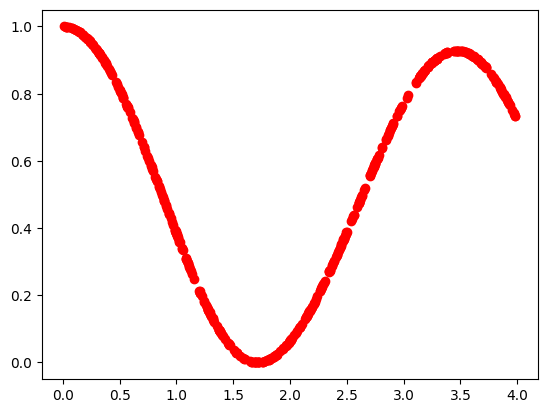

In [ ]:
# Define five non-uniformly spaced sample points
p_signal = np.sort(np.random.uniform(low=0,high=1,size=4))  # Non-uniform sample times

y_signal = np.sin(4*np.pi*p_signal) + 2

# Define a small set of frequency locations where we evaluate the NUDFT
frequencies = np.sort(np.random.uniform(low=0,high=len(y_signal),size=500)) #np.linspace(0,len(y),500)

# Compute NUDFT
n = len(p_signal)
F_nudft = np.array([np.sum(y_signal * np.exp(-2j * np.pi * f * p_signal)) for f in frequencies])

plt.scatter(frequencies, (np.abs(F_nudft)-np.min(np.abs(F_nudft)))/(np.max(np.abs(F_nudft))-np.min(np.abs(F_nudft))), color='red', label='Sampled Points')

In [ ]:
optimized_hamiltonians_p = construct_minimal_hamiltonians(p_signal)

for key, matrix in optimized_hamiltonians_p.items():
    print(f"{key}:\n{matrix}\n")

diff_p = verify_pqc_reconstruction(optimized_hamiltonians_p, p_signal)

H_0:
[[0.         0.        ]
 [0.         0.41437866]]

H_1:
[[0.         0.        ]
 [0.         0.66680912]]

H_2:
[[0.         0.        ]
 [0.         0.98175051]]

H_3:
[[0.         0.        ]
 [0.         0.69677591]]

H_4:
[[0 0]
 [0 0]]


--- PQC Verification ---
Generated differences: [-2.759714, -2.345336, -2.092905, -2.062938, -1.930957, -1.777964, -1.678526, -1.64856, -1.426096, -1.396129, -1.366162, -1.363585, -1.264148, -1.234181, -1.111155, -1.081188, -1.011717, -0.981751, -0.951784, -0.949206, -0.796213, -0.72932, -0.699353, -0.696776, -0.666809, -0.597339, -0.567372, -0.537405, -0.444345, -0.414379, -0.384412, -0.381835, -0.314941, -0.284975, -0.282397, -0.25243, -0.129404, -0.099437, -0.032544, -0.029967, 0.0, 0.029967, 0.032544, 0.099437, 0.129404, 0.25243, 0.282397, 0.284975, 0.314941, 0.381835, 0.384412, 0.414379, 0.444345, 0.537405, 0.567372, 0.597339, 0.666809, 0.696776, 0.699353, 0.72932, 0.796213, 0.949206, 0.951784, 0.981751, 1.011717, 1.081188, 1.111155, 1

In [ ]:
def log_tran(y):
    return np.log(y)/y 


eta_2 = log_tran(y_signal)

optimized_hamiltonians_eta = construct_minimal_hamiltonians(eta_2)


diff_eta2 = verify_pqc_reconstruction(optimized_hamiltonians_eta, eta_2)

optimized_hamiltonians_eta = {k:v*1j for k,v in optimized_hamiltonians_eta.items()}
eta_2 = 1j*eta_2
diff_eta2 = 1j*diff_eta2
for key, matrix in optimized_hamiltonians_eta.items():
    print(f"{key}:\n{matrix}\n")



--- PQC Verification ---
Generated differences: [-1.159121, -1.057964, -0.956807, -0.836169, -0.791734, -0.791497, -0.735012, -0.690577, -0.69034, -0.633855, -0.58942, -0.589183, -0.513217, -0.468781, -0.468545, -0.424346, -0.424109, -0.423873, -0.41206, -0.367624, -0.367388, -0.323189, -0.322952, -0.322716, -0.310902, -0.266467, -0.266231, -0.222032, -0.221795, -0.221559, -0.145829, -0.145592, -0.101393, -0.101157, -0.100921, -0.056722, -0.056485, -0.044672, -0.044435, -0.000236, 0.0, 0.000236, 0.044435, 0.044672, 0.056485, 0.056722, 0.100921, 0.101157, 0.101393, 0.145592, 0.145829, 0.221559, 0.221795, 0.222032, 0.266231, 0.266467, 0.310902, 0.322716, 0.322952, 0.323189, 0.367388, 0.367624, 0.41206, 0.423873, 0.424109, 0.424346, 0.468545, 0.468781, 0.513217, 0.589183, 0.58942, 0.633855, 0.69034, 0.690577, 0.735012, 0.791497, 0.791734, 0.836169, 0.956807, 1.057964, 1.159121]
Target P_n: [0.101157, 0.322952, 0.367388, 0.367624]
✅ Success: True

H_0:
[[0.+0.j         0.+0.j        ]
 [0

In [ ]:
# unit test 
# x_pn == \sum_eta_2 c exp(-ieta2 y)

s = 0 
for eta in eta_2:
    print(np.exp(-1*eta*y_signal[0]))
    s += np.exp(-1*eta*y_signal[0])
y_signal[0],s

# works, but many contributions!

(0.9935893598478913-0.11304947588139265j)
(0.9165382437350602-0.39994705621000803j)
(0.9164323266449614-0.4001896933706598j)
(0.9352989613924724-0.3538585209065376j)


(1.1199585438623942, (3.7618588916203852-1.267044746368598j))

In [ ]:
def nuft_looped(f, p_arr, y_arr):
    sum_total = 0  # Initialize sum
    
    for p in p_arr:  # Loop over positions
        for y in y_arr:
            term = y * np.exp(-2j * np.pi * f * p)  # Compute term
            sum_total += term  # Accumulate sum
    
    return sum_total

def nuft_original(f, p_arr, y_arr):
    sum_total = 0  # Initialize sum
    
    for i in range(len(p_arr)):  # Loop over positions
        p = p_arr[i]  # Get position
        y = y_arr[i]  # Get corresponding y value
        
        term = y * np.exp(-2j * np.pi * f * p)  # Compute term
        sum_total += term  # Accumulate sum
    
    return sum_total


# def log_transformation(y):
#     return 1j * np.log(y) / y

# what are the things I need to set?
# only contribute if index pn is corresponding to y 
# only contribute pn that are part of the original pn 
# only contribute eta2 that are part of the original
# lookup_dict = {k:v for k,v in zip(y_signal, p_signal) }

def nuft_pqc_partial(f, p_arr, y_arr, eta_arr):
    """Computes the NUDFT using precomputed eta_arr (no inner loop needed)."""
    total_sum = 0
    for i in range(len(p_arr)):
        p = p_arr[i]
        y = y_arr[i]

        for eta in eta_arr:
            if np.isclose(np.exp(-1j*eta*y),y):
        
                term = np.exp(-1j * eta * y) * np.exp(-2j * np.pi * f * p)
                total_sum += term
                break 
    return total_sum

# ee = log_transformation(y_signal)
F_nudft = np.array([nuft_original(f, p_signal, y_signal) for f in tqdm(frequencies, desc="Computing NUFT")])
F_nudft_looped = np.array([nuft_looped(f, p_signal, y_signal) for f in tqdm(frequencies, desc="Computing NUFT")])
partial_pqc = np.array([nuft_pqc_partial(f, p_signal, y_signal, eta_2) for f in tqdm(frequencies, desc="Computing NUFT")])

Computing NUFT:   0%|          | 0/500 [00:00<?, ?it/s]

Computing NUFT: 100%|██████████| 500/500 [00:00<00:00, 5125.83it/s]


In [ ]:
def nuft_pqc(f, y, p_arr, eta_arr):
        
    sum = 0 
    for p in p_arr:
        for eta in eta_arr:
            sum += np.exp(-1j * eta * y) * np.exp(-2j * np.pi * f * p)
    return sum

full_pqc = np.zeros_like(frequencies)
for inx, f in enumerate(tqdm(frequencies)):
    for y in y_signal:
        full_pqc[inx] += nuft_pqc(f, y, diff_p, diff_eta2) 


  0%|          | 0/500 [00:00<?, ?it/s]/tmp/ipykernel_66787/2290396480.py:12: ComplexWarning: Casting complex values to real discards the imaginary part
  full_pqc[inx] += nuft_pqc(f, y, diff_p, diff_eta2)
100%|██████████| 500/500 [00:20<00:00, 24.47it/s]


/home/felix/vscodeProjects/SAR-QML/.venv/lib/python3.11/site-packages/matplotlib/cbook.py:1762: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/home/felix/vscodeProjects/SAR-QML/.venv/lib/python3.11/site-packages/matplotlib/collections.py:197: ComplexWarning: Casting complex values to real discards the imaginary part
  offsets = np.asanyarray(offsets, float)


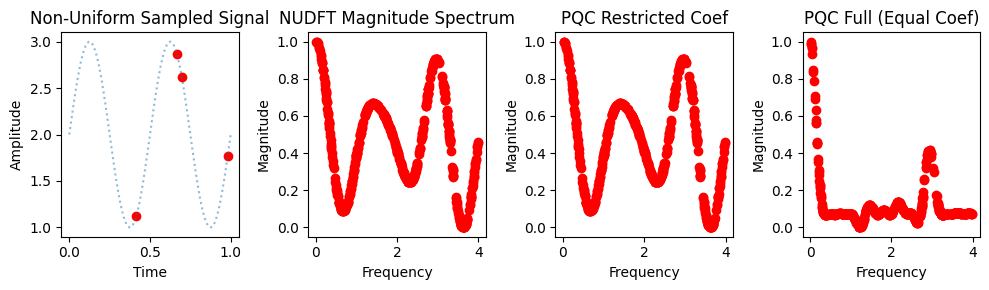

In [ ]:
# Plot original signal and its NUDFT magnitude
fig, ax = plt.subplots(1, 4, figsize=(10, 3))

# Plot the sampled signal
t = np.linspace(0, 1, 100)
ax[0].scatter(p_signal, y_signal, color='red', label='Sampled Points')
ax[0].plot(t, np.sin(4*np.pi*t)+2, linestyle='dotted', alpha=0.5)
ax[0].set_title("Non-Uniform Sampled Signal")
ax[0].set_xlabel("Time")
ax[0].set_ylabel("Amplitude")

ax[1].scatter(frequencies, (F_nudft-np.min(F_nudft))/(np.max(F_nudft)-np.min(F_nudft)), color='red', label='Sampled Points')
ax[1].set_title("NUDFT Magnitude Spectrum")
ax[1].set_xlabel("Frequency")
ax[1].set_ylabel("Magnitude")

ax[2].scatter(frequencies, (partial_pqc-np.min(partial_pqc))/(np.max(partial_pqc)-np.min(partial_pqc)), color='red', label='Sampled Points')
ax[2].set_title("PQC Restricted Coef")
ax[2].set_xlabel("Frequency")
ax[2].set_ylabel("Magnitude")

ax[3].scatter(frequencies, (full_pqc-np.min(full_pqc))/(np.max(full_pqc)-np.min(full_pqc)), color='red', label='Sampled Points')
ax[3].set_title("PQC Full (Equal Coef)")
ax[3].set_xlabel("Frequency")
ax[3].set_ylabel("Magnitude")

plt.tight_layout()
plt.show()

# Function Fitting

In [ ]:
import pennylane as qml
import numpy as np
from scipy.linalg import expm
from pennylane import numpy as pp


def square_loss(predictions, targets):
    return pp.sum(pp.abs(predictions - targets) ** 2)

def naive_nuft(f, x_eta, target_y, optimized_hamiltonians_p, optimized_hamiltonians_eta):

    L = 1  # Number of layers (previously called r)
    

    dev = qml.device("default.qubit", wires=1) 

    def S_p(f): 
        """Data encoding circuit block using precomputed Hamiltonian exponentials."""
        for key in sorted(optimized_hamiltonians_p.keys()):  
            qml.QubitUnitary(expm(-1j * f * optimized_hamiltonians_p[key]*2*pp.pi), wires=0)

    def S_eta(x_eta): 
        """Data encoding circuit block using precomputed Hamiltonian exponentials."""
        
        for key in sorted(optimized_hamiltonians_eta.keys()):
            qml.QubitUnitary(expm(-1j * x_eta * optimized_hamiltonians_eta[key]), wires=0)


    @qml.qnode(dev)
    def nuft_quantum_model(f=None, x_eta=None):
        qml.Hadamard(wires=0)
        for _ in range(L):
            S_p(f)
            S_eta(x_eta)
        return qml.expval(qml.PauliZ(wires=0))

    def cost(f, x_eta, y):
        predictions = pp.array([nuft_quantum_model(f=f_, x_eta=xe) for f_, xe in zip(f, x_eta)])
        return square_loss(predictions, y) #np.mean((np.array(predictions) - np.array(y)) ** 2)  # Square loss

    
    cst = [cost(f, x_eta, target_y)]  # Initial cost

    
    predictions = pp.array([nuft_quantum_model(f=f_, x_eta=xe) for f_, xe in zip(f, x_eta)])
    return predictions, nuft_quantum_model


H_0:
[[0.   0.  ]
 [0.   0.35]]

H_1:
[[0.  0. ]
 [0.  0.6]]

H_2:
[[0.  0. ]
 [0.  0.8]]

H_3:
[[0.   0.  ]
 [0.   0.97]]


--- PQC Verification ---
Generated differences: [-2.72, -2.37, -2.12, -2.02, -1.92, -1.77, -1.75, -1.57, -1.52, -1.42, -1.4, -1.32, -1.22, -1.17, -1.15, -1.12, -1.05, -0.97, -0.95, -0.82, -0.8, -0.78, -0.77, -0.72, -0.62, -0.6, -0.55, -0.52, -0.45, -0.43, -0.42, -0.37, -0.35, -0.25, -0.2, -0.18, -0.17, -0.15, -0.08, -0.02, 0.0, 0.02, 0.08, 0.15, 0.17, 0.18, 0.2, 0.25, 0.35, 0.37, 0.42, 0.43, 0.45, 0.52, 0.55, 0.6, 0.62, 0.72, 0.77, 0.78, 0.8, 0.82, 0.95, 0.97, 1.05, 1.12, 1.15, 1.17, 1.22, 1.32, 1.4, 1.42, 1.52, 1.57, 1.75, 1.77, 1.92, 2.02, 2.12, 2.37, 2.72]
Target P_n: [0.35, 0.6, 0.8, 0.97]
✅ Success: True

Len 81
H_0:
[[ 0.          0.        ]
 [ 0.         -0.04555389]]

H_1:
[[ 0.          0.        ]
 [ 0.         -0.36670367]]

H_2:
[[ 0.          0.        ]
 [ 0.         -0.24440986]]

H_3:
[[ 0.          0.        ]
 [ 0.         -0.30010252]]

H_4:
[

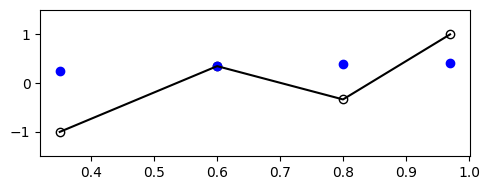

In [ ]:
samples = 4
x_signal = np.round(np.sort(np.random.uniform(low=0,high=1,size=samples)),2)
y_signal = np.sin(4*np.pi*x_signal) + 2

frequencies = np.round(np.sort(np.random.uniform(low=0,high=len(y_signal),size=samples)),2) #np.linspace(0,len(y),500)

n = len(x_signal)
F_nudft_ = np.array([np.sum(y_signal * np.exp(-2j * np.pi * f * x_signal)) for f in frequencies])
F_nudft = F_nudft_.real  
F_nudft = (F_nudft - np.min(F_nudft)) / (np.max(F_nudft) - np.min(F_nudft)) * 2 - 1

optimized_hamiltonians_p = construct_minimal_hamiltonians(x_signal)

for key, matrix in optimized_hamiltonians_p.items():
    print(f"{key}:\n{matrix}\n")

diff_p = verify_pqc_reconstruction(optimized_hamiltonians_p, x_signal)

print("Len", len(diff_p))

def log_transformation(y):
    return -1*np.log(y)/y 


eta_2 = log_transformation(y_signal)

optimized_hamiltonians_eta = construct_minimal_hamiltonians(eta_2)

for key, matrix in optimized_hamiltonians_eta.items():
    print(f"{key}:\n{matrix}\n")

diff_eta2 = verify_pqc_reconstruction(optimized_hamiltonians_eta, eta_2)
optimized_hamiltonians_eta = {k:v*1j for k,v in optimized_hamiltonians_eta.items()}

predictions, nuft_quantum_model = naive_nuft(pp.array(frequencies), pp.array(x_signal),  pp.array(F_nudft), optimized_hamiltonians_p, optimized_hamiltonians_eta)



fig, axs = plt.subplots(1, figsize=(5,2))

axs.plot(x_signal, F_nudft.real, c='black')
axs.scatter(x_signal, F_nudft.real, facecolor='white', edgecolor='black')
axs.scatter(x_signal, predictions.real, c='blue')
axs.set_ylim(-1.5,1.5)


plt.tight_layout()

tensor([0.18035829, 0.36936778, 0.39453191, 0.39453191], requires_grad=True)

In [ ]:
import pennylane as qml
import numpy as np
from scipy.linalg import expm
from pennylane import numpy as pp


def square_loss(predictions, targets):
    return pp.sum(pp.abs(predictions - targets) ** 2)

def train_nuft(f, x_eta, target_y, optimized_hamiltonians_p, optimized_hamiltonians_eta):

    L = 1  # Number of layers (previously called r)
    total_params = (2 * L + 1) * 3  # Correct parameter count
    weights = 2 * pp.pi * pp.random.random(size=total_params)
    max_steps = 500
    opt = qml.AdamOptimizer(0.01)#qml.AdamOptimizer(0.1)
    batch_size = 4
    
    dev = qml.device("default.qubit", wires=1) 

    def S_p(f): 
        """Data encoding circuit block using precomputed Hamiltonian exponentials."""
        for key in sorted(optimized_hamiltonians_p.keys()):  
            qml.QubitUnitary(expm(-1j * f * optimized_hamiltonians_p[key]*2*pp.pi), wires=0)

    def S_eta(x_eta): 
        """Data encoding circuit block using precomputed Hamiltonian exponentials."""
        
        for key in sorted(optimized_hamiltonians_eta.keys()):
            qml.QubitUnitary(expm(-1j * x_eta * optimized_hamiltonians_eta[key]), wires=0)

    def W(theta):
        """Trainable circuit block."""
        qml.Rot(theta[0], theta[1], theta[2], wires=0)

    @qml.qnode(dev)
    def nuft_quantum_model(weights, f=None, x_eta=None):
        ptr = 0
        # qml.Hadamard(wires=0)
        # W(weights[ptr:ptr+3])
        for _ in range(L):
            W(weights[ptr:ptr+3])
            ptr += 3
            S_p(f)
            W(weights[ptr:ptr+3])  # Add trainable layer after S_p
            ptr += 3
            S_eta(x_eta)
            # W(weights[ptr:ptr+3])  # Add trainable layer after S_eta
            # ptr += 3
        # Final layer
        W(weights[ptr:ptr+3])
        return qml.expval(qml.PauliZ(wires=0))

# qml.math.real(nuft_quantum_model(weights, x_p=xp, x_eta=xe))
    def cost(weights, f, x_eta, y):
        predictions = pp.array([nuft_quantum_model(weights, f=f_, x_eta=xe) for f_, xe in zip(f, x_eta)])
        return square_loss(predictions, y) #np.mean((np.array(predictions) - np.array(y)) ** 2)  # Square loss

    
    cst = [cost(weights, f, x_eta, target_y)]  # Initial cost

    for step in range(max_steps):

        # Select batch of data
        batch_index = pp.random.randint(0, len(f), (batch_size,))
        x_p_batch = f[batch_index]
        x_eta_batch = x_eta[batch_index]
        y_batch = target_y[batch_index]

        # Update the weights by one optimizer step
        weights = opt.step(lambda w: cost(w, x_p_batch, x_eta_batch, y_batch), weights)

        # Save and possibly print the current cost
        c = cost(weights, f, x_eta, target_y)
        cst.append(c)
        if (step + 1) % 10 == 0:
            print(f"Adaptive Cost at step {step + 1}: {c}")

    predictions = pp.array([nuft_quantum_model(weights, f=f_, x_eta=xe) for f_, xe in zip(f, x_eta)])
    return predictions, nuft_quantum_model, weights


In [ ]:
samples = 4
x_signal = np.round(np.sort(np.random.uniform(low=0,high=1,size=samples)),2)
y_signal = np.sin(4*np.pi*x_signal) + 2

frequencies = np.round(np.sort(np.random.uniform(low=0,high=len(y_signal),size=samples)),2) #np.linspace(0,len(y),500)

n = len(x_signal)
F_nudft_ = np.array([np.sum(y_signal * np.exp(-2j * np.pi * f * x_signal)) for f in frequencies])
F_nudft = F_nudft_.real  
F_nudft = (F_nudft - np.min(F_nudft)) / (np.max(F_nudft) - np.min(F_nudft)) * 2 - 1

optimized_hamiltonians_p = construct_minimal_hamiltonians(x_signal)

for key, matrix in optimized_hamiltonians_p.items():
    print(f"{key}:\n{matrix}\n")

diff_p = verify_pqc_reconstruction(optimized_hamiltonians_p, x_signal)

print("Len", len(diff_p))

def log_transformation(y):
    return -1*np.log(y)/y 


eta_2 = log_transformation(y_signal)

optimized_hamiltonians_eta = construct_minimal_hamiltonians(eta_2)

for key, matrix in optimized_hamiltonians_eta.items():
    print(f"{key}:\n{matrix}\n")

diff_eta2 = verify_pqc_reconstruction(optimized_hamiltonians_eta, eta_2)
optimized_hamiltonians_eta = {k:v*1j for k,v in optimized_hamiltonians_eta.items()}

predictions, nuft_quantum_model, weights = train_nuft(pp.array(frequencies), pp.array(x_signal),  pp.array(F_nudft), optimized_hamiltonians_p, optimized_hamiltonians_eta)


H_0:
[[0.   0.  ]
 [0.   0.01]]

H_1:
[[0.   0.  ]
 [0.   0.23]]

H_2:
[[0.  0. ]
 [0.  0.3]]

H_3:
[[0.   0.  ]
 [0.   0.86]]


--- PQC Verification ---
Generated differences: [-1.4, -1.39, -1.38, -1.17, -1.16, -1.15, -1.1, -1.09, -1.08, -0.94, -0.93, -0.92, -0.87, -0.86, -0.85, -0.8, -0.79, -0.78, -0.64, -0.63, -0.62, -0.57, -0.56, -0.55, -0.54, -0.53, -0.52, -0.34, -0.33, -0.32, -0.31, -0.3, -0.29, -0.24, -0.23, -0.22, -0.08, -0.07, -0.06, -0.01, 0.0, 0.01, 0.06, 0.07, 0.08, 0.22, 0.23, 0.24, 0.29, 0.3, 0.31, 0.32, 0.33, 0.34, 0.52, 0.53, 0.54, 0.55, 0.56, 0.57, 0.62, 0.63, 0.64, 0.78, 0.79, 0.8, 0.85, 0.86, 0.87, 0.92, 0.93, 0.94, 1.08, 1.09, 1.1, 1.15, 1.16, 1.17, 1.38, 1.39, 1.4]
Target P_n: [0.01, 0.23, 0.3, 0.86]
✅ Success: True

Len 81
H_0:
[[ 0.         0.       ]
 [ 0.        -0.3547343]]

H_1:
[[ 0.         0.       ]
 [ 0.        -0.3603644]]

H_2:
[[ 0.          0.        ]
 [ 0.         -0.24440986]]

H_3:
[[ 0.          0.        ]
 [ 0.         -0.01725212]]

H_4:
[[0 

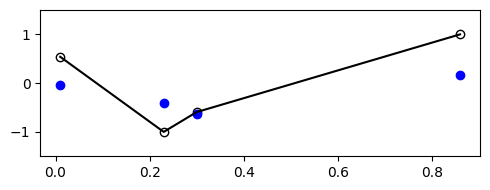

In [ ]:

fig, axs = plt.subplots(1, figsize=(5,2))

axs.plot(x_signal, F_nudft.real, c='black')
axs.scatter(x_signal, F_nudft.real, facecolor='white', edgecolor='black')
axs.scatter(x_signal, predictions.real, c='blue')
axs.set_ylim(-1.5,1.5)


plt.tight_layout()

In [ ]:
len(optimized_hamiltonians_eta),len(optimized_hamiltonians_p)

(5, 4)

(<Figure size 1600x200 with 1 Axes>, <Axes: >)

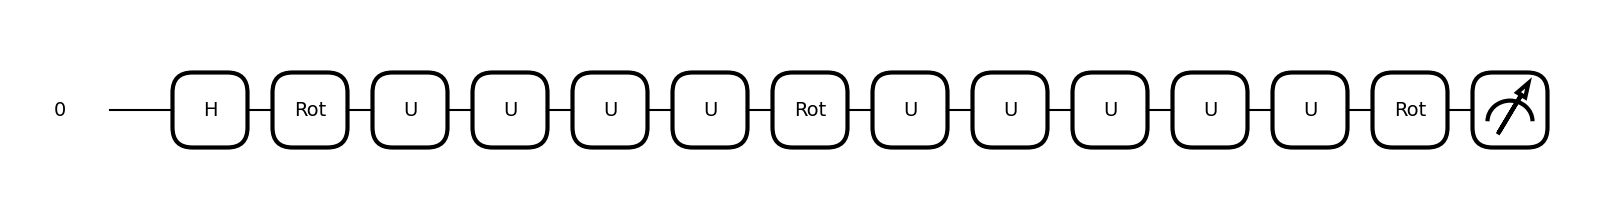

In [ ]:
qml.draw_mpl(nuft_quantum_model)(weights, x_p=x_signal[0], x_eta=frequencies[0])